# 감귤 및 만감류 도매시장 판매데이터(`data/kat*.csv`, `data/mkat*.csv`) 전처리 및 다차원 EDA 분석
> **작성 목적**: `data/` 디렉터리에 수집된 전국 32개 공영도매시장 감귤 거래 정산 데이터(`data/kat*.csv`, `data/mkat*.csv` 만감류 포함 총 554개 파일, 약 173만 건)를 통합 전처리하고, **경매 vs 수의계약 제외 비교, 날짜별, 등급별, 종류별(품종별), 크기별** 판매수량(거래물량)과 판매가격을 심층 분석 및 시각화합니다.
> **aT 공영도매시장 공식 표준 품종 코드 매핑**:
> - `gds_sclsf_cd` 07: **한라봉**
> - `gds_sclsf_cd` 08: **천혜향**
> - `gds_sclsf_cd` 09: **레드향**
> - `gds_sclsf_cd` 10: **카라향**
> - `gds_sclsf_cd` 11: **황금향**

---

### 분석 파이프라인 목차
1. **환경 설정 및 한글 폰트 설정**: 데이터 분석 라이브러리 로드 및 시각화 환경 구성 (`Malgun Gothic`)
2. **데이터 수집 및 병합 (Ingestion)**: `data/kat*.csv` 및 `data/mkat*.csv`(만감류) 총 554개 분할 파일 일괄 로드 및 중복 레코드 정제
3. **데이터 정제 및 전처리 (Preprocessing & Cleaning)**:
   - 거래일자 날짜형(`datetime`) 변환 및 시계열 파생변수 생성
   - **aT 공식 표준 품종 코드 매핑 (07: 한라봉, 08: 천혜향, 09: 레드향, 10: 카라향, 11: 황금향)**
   - 음수/오류 거래 및 극단 이상치 제거
   - 핵심 지표(`volume_kg`, `box_qty`, `total_price`, `box_price`, `unit_price_kg`) 산출
4. **【거래유형 분석】 수의계약 제외에 따른 판매가격 변동 검토 (경매 vs 수의계약)**:
   - 거래유형별(경매 vs 수의계약) 물량 및 단가 격차 비교
   - 수의계약 제외 시 품종별/등급별 평균 판매가격 변동폭(%) 검토
   - 시계열(월별) 단가 추이 비교 (전체 vs 수의계약 제외 순수 경매)
5. **[날짜별] 판매수량 및 판매가격 시계열 분석**: 일별/월별 물량 추이 및 단가 변동 수급 분석 (2축 Dual-Axis 차트)
6. **[등급별] 판매수량 및 판매가격 분석**: 등급별 점유율, 평균 단가 및 가격 분포(Boxplot)
7. **[종류별] 판매수량 및 판매가격 분석**: 주요 품종별(하우스감귤, 조생귤, 한라봉, 천혜향, 레드향 등) 물량 및 단가 프리미엄 분석
8. **[크기별] 판매수량 및 판매가격 분석 (품종별 세부 분류 포함)**:
   - 8-1) 전체 감귤 크기 규격별 판매물량 및 단가 분석 (50내 -> 45내 -> 40내 -> 35내 -> 소 -> 중 -> 대 -> 특대)
   - 8-2) **주요 품종별(하우스감귤, 조생귤, 한라봉, 천혜향, 레드향) 크기 규격별 세부 분류 및 단가 비교**
   - 8-4) **상자 크기별(3kg, 5kg, 10kg) x 과수 규격(50내/45내/40내/35내) 품종별 평균가격 비교**
9. **[크기별 × 품종별] 항목별 날짜에 따른 거래량 및 가격 시계열 분석**:
   - 9-1) 품종별 주요 크기 규격의 월별 거래물량(톤) 시계열 추이
   - 9-2) 품종별 주요 크기 규격의 월별 kg당 평균가격(원/kg) 시계열 추이
   - 9-3) 대표 품종 및 크기 항목별 날짜에 따른 거래량 & 가격 2축(Dual-Axis) 추이
   - 9-4) [품종 × 등급] 및 [품종 × 크기] 교차 단가 히트맵
10. **전처리 완료 데이터 내보내기 (Export)**: 모델링 및 후속 분석용 정제 데이터셋 CSV 저장


## 1. 환경 설정 및 한글 폰트 설정
- 시각화 시 한글 깨짐 방지를 위해 `Malgun Gothic` 폰트 및 음수 기호 설정을 적용합니다.

In [2]:
import os
import glob
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# 경고 메시지 무시
warnings.filterwarnings('ignore')

# Matplotlib 한글 폰트 및 마이너스 부호 설정
plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Seaborn 테마 설정
sns.set_theme(style='whitegrid', font='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

print("환경 설정 완료: pandas, numpy, matplotlib, seaborn 로드 성공")

환경 설정 완료: pandas, numpy, matplotlib, seaborn 로드 성공


## 2. 데이터 수집 및 병합 (Data Ingestion)
- `data/` 디렉터리 내의 일반 감귤 데이터(`data/kat*.csv`) 및 만감류 전용 경매 데이터(`data/mkat*.csv`, 총 554개 분할 파일)를 탐색하여 병합합니다.
- 0바이트 빈 파일을 필터링하고 중복 데이터를 제거하여 단일 데이터프레임으로 통합합니다.


In [3]:
# 1) data/ 디렉터리 내 감귤(kat*.csv) 및 만감류(mkat*.csv) 전체 파일 검색 (fallback: output/)
data_dir = Path("data")
data_files = sorted(list(set(
    glob.glob(str(data_dir / "kat*.csv")) +
    glob.glob(str(data_dir / "mkat*.csv")) +
    glob.glob(str(data_dir / "*kat*.csv"))
)))

if not data_files:
    print("data/ 디렉터리에 데이터 파일이 없어 output/ 디렉터리에서 검색합니다.")
    data_dir = Path("output")
    data_files = sorted(list(set(
        glob.glob(str(data_dir / "kat*.csv")) +
        glob.glob(str(data_dir / "mkat*.csv")) +
        glob.glob(str(data_dir / "*kat*.csv"))
    )))

# 0바이트 파일 및 _all.csv 제외한 유효 CSV 파일 선택
valid_files = [f for f in data_files if '_all.csv' not in f and os.path.getsize(f) > 50]
print(f"발견된 유효한 데이터 파일 수: {len(valid_files)}개 (대상 디렉터리: {data_dir.resolve()})")

# 2) 필요한 핵심 컬럼 선별 로드 (거래구분 trd_se 포함)
target_cols = [
    'trd_clcln_ymd', 'whsl_mrkt_cd', 'whsl_mrkt_nm', 'trd_se',
    'gds_sclsf_cd', 'gds_sclsf_nm', 'grd_cd', 'grd_nm', 'sz_cd', 'sz_nm',
    'pkg_cd', 'pkg_nm', 'unit_nm', 'unit_qty', 'unit_tot_qty', 'avgprc', 'totprc'
]

t0 = time.time()
dfs = []
for file_path in valid_files:
    try:
        df_sub = pd.read_csv(file_path, usecols=lambda c: c in target_cols, low_memory=False, encoding='utf-8-sig')
        dfs.append(df_sub)
    except Exception as exc:
        print(f"파일 로드 오류 건너뜀: {file_path} - {exc}")

df_raw = pd.concat(dfs, ignore_index=True)
elapsed = time.time() - t0
print(f"\n데이터 로드 완료! (소요시간: {elapsed:.2f}초)")
print(f"- 원본 데이터 총 행 수: {len(df_raw):,} 건")
print(f"- 원본 데이터 컬럼 수: {df_raw.shape[1]} 개")

# 중복 레코드 제거
raw_count = len(df_raw)
df_raw = df_raw.drop_duplicates()
print(f"- 중복 제거 후 행 수: {len(df_raw):,} 건 ({raw_count - len(df_raw):,}건 중복 제거됨)")
df_raw.head(3)


발견된 유효한 데이터 파일 수: 566개 (대상 디렉터리: D:\hongdonjoo\ai\project\ugasungsi\data)

데이터 로드 완료! (소요시간: 27.63초)
- 원본 데이터 총 행 수: 1,728,626 건
- 원본 데이터 컬럼 수: 17 개
- 중복 제거 후 행 수: 1,726,915 건 (1,711건 중복 제거됨)


,avgprc,gds_sclsf_cd,gds_sclsf_nm,grd_cd,grd_nm,pkg_cd,pkg_nm,sz_cd,sz_nm,totprc,trd_clcln_ymd,trd_se,unit_nm,unit_qty,unit_tot_qty,whsl_mrkt_cd,whsl_mrkt_nm
0,6519.048,1,조생귤,12,상,101,상자,100,.,6154700.0,2021-01-04,경매,kg,5.0,4485.0,210009,부산반여
1,7994.030,1,조생귤,12,상,101,상자,100,.,21994500.0,2021-01-04,경매,kg,5.0,12630.0,210009,부산반여
2,15383.333,1,조생귤,12,상,101,상자,100,.,5875500.0,2021-01-04,경매,kg,10.0,4140.0,210009,부산반여


## 3. 데이터 정제 및 전처리 (Data Cleaning & Feature Engineering)

### 정제 작업 상세:
1. **날짜 변환 및 파생변수 생성**: `trd_clcln_ymd` 문자열을 `datetime`으로 변환 후 `year`, `month`, `year_month`, `weekday` 생성
2. **거래 무효치 필터링**: 음수/0 거래수량 및 거래금액 정제 (`unit_tot_qty > 0`, `totprc > 0`, `avgprc > 0`)
3. **aT 공영도매시장 공식 표준 품종 코드 매핑**:
   - `gds_sclsf_cd` 07 (7) $
ightarrow$ **한라봉** (정상 복원)
   - `gds_sclsf_cd` 08 (8) $
ightarrow$ **천혜향** (정상 복원)
   - `gds_sclsf_cd` 09 (9) $
ightarrow$ **레드향**
   - `gds_sclsf_cd` 10 $
ightarrow$ **카라향**
   - `gds_sclsf_cd` 11 $
ightarrow$ **황금향**
   - 그 외 기존 소분류명 및 일반 감귤 표준 코드 적용
4. **거래구분(`trd_se`) 정제**: 경매, 수의계약(정가수의), 기타 거래 구분 컬럼(`trd_type`) 생성
5. **등급 및 크기 명칭 표준화**: 잡음 기호(`.`, 공백)를 `무등급/미지정`, `미지정`으로 표준화
6. **핵심 분석 지표 생성**:
   - `volume_kg`: 총 판매물량 (kg)
   - `box_qty`: 환산 판매상자 수 (`unit_tot_qty / unit_qty`)
   - `total_price`: 총 판매금액 (원)
   - `box_price`: 상자(포장)당 평균가격 (원/상자)
   - `unit_price_kg`: kg당 평균 판매단가 (`total_price / volume_kg`, 원/kg)
7. **단가 이상치 필터링**: kg당 단가가 100원 미만이거나 100,000원 초과인 극단 입력오류 정제

In [4]:
df = df_raw.copy()

# 1) 날짜 변환 및 시계열 파생변수
df['date'] = pd.to_datetime(df['trd_clcln_ymd'], errors='coerce')
df = df.dropna(subset=['date']).copy()
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['year_month'] = df['date'].dt.to_period('M').astype(str)
df['day_name'] = df['date'].dt.day_name()
weekday_kor = {'Monday': '월', 'Tuesday': '화', 'Wednesday': '수', 'Thursday': '목', 'Friday': '금', 'Saturday': '토', 'Sunday': '일'}
df['weekday'] = df['day_name'].map(weekday_kor)

# 2) 유효 거래 수량 및 금액 필터링 (음수 및 0 정산내역 제거)
valid_mask = (df['unit_tot_qty'] > 0) & (df['totprc'] > 0) & (df['avgprc'] > 0)
df = df[valid_mask].copy()

# 3) aT 공영도매시장 공식 표준 품종 코드 매핑 (07: 한라봉, 08: 천혜향, 09: 레드향, 10: 카라향, 11: 황금향)
citrus_variety_map = {
    0: '감귤(일반)', '0': '감귤(일반)', '00': '감귤(일반)',
    1: '조생귤', '1': '조생귤', '01': '조생귤',
    2: '중생귤', '2': '중생귤', '02': '중생귤',
    3: '만생귤', '3': '만생귤', '03': '만생귤',
    4: '비가림감귤', '4': '비가림감귤', '04': '비가림감귤',
    5: '하우스감귤', '5': '하우스감귤', '05': '하우스감귤',
    6: '극조생감귤', '6': '극조생감귤', '06': '극조생감귤',
    7: '한라봉', '7': '한라봉', '07': '한라봉',
    8: '천혜향', '8': '천혜향', '08': '천혜향',
    9: '레드향', '9': '레드향', '09': '레드향',
    10: '카라향', '10': '카라향',
    11: '황금향', '11': '황금향',
    12: '하루미', '12': '하루미',
    13: '온주', '13': '온주',
    15: '성전', '15': '성전',
    17: '홍미향', '17': '홍미향',
    19: '타이벡감귤', '19': '타이벡감귤',
    20: '풋귤(청귤)', '20': '풋귤(청귤)',
    23: '미니향', '23': '미니향',
    32: '유라와세', '32': '유라와세',
    34: '산하홍', '34': '산하홍',
    98: '감귤(수입)', '98': '감귤(수입)',
    99: '기타', '99': '기타'
}

# aT 표준 만감류 코드 오버라이드 매핑 (kat 데이터 결측 코드 보정용)
user_override_map = {
    7: '한라봉', '7': '한라봉', '07': '한라봉', 7.0: '한라봉',
    8: '천혜향', '8': '천혜향', '08': '천혜향', 8.0: '천혜향',
    9: '레드향', '9': '레드향', '09': '레드향', 9.0: '레드향',
    10: '카라향', '10': '카라향', 10.0: '카라향',
    11: '황금향', '11': '황금향', 11.0: '황금향'
}

# gds_sclsf_nm(문자열 품종명) 최우선 보존(mkat 및 kat 공통) 후, 결측 시 코드 매핑 적용
df['variety'] = (
    df['gds_sclsf_nm']
    .combine_first(df['gds_sclsf_cd'].map(user_override_map))
    .combine_first(df['gds_sclsf_cd'].map(citrus_variety_map))
    .fillna('기타')
)

# 4) 거래구분(trd_se) 표준화: 경매 vs 수의계약(정가수의)
df['trd_se_raw'] = df['trd_se'].fillna('기타').astype(str)
df['is_negotiated'] = df['trd_se_raw'].str.contains('수의', na=False)
df['is_auction'] = df['trd_se_raw'].str.contains('경매', na=False)
df['trd_type'] = np.where(df['is_negotiated'], '수의계약', np.where(df['is_auction'], '경매', '기타'))

# 5) 등급(Grade) 표준화
df['grade'] = df['grd_nm'].fillna('.').astype(str).str.strip()
df['grade'] = df['grade'].replace({'.': '무등급/미지정', '': '무등급/미지정', 'nan': '무등급/미지정'})

# 6) 크기(Size) 표준화
df['size'] = df['sz_nm'].fillna('.').astype(str).str.strip()
df['size'] = df['size'].replace({'.': '미지정', '': '미지정', 'nan': '미지정'})

# 7) 핵심 분석 수치 지표 계산
df['volume_kg'] = pd.to_numeric(df['unit_tot_qty'], errors='coerce').fillna(0.0)
df['unit_weight'] = pd.to_numeric(df['unit_qty'], errors='coerce').fillna(0.0)
df['box_qty'] = np.where(df['unit_weight'] > 0, df['volume_kg'] / df['unit_weight'], np.nan)
df['total_price'] = pd.to_numeric(df['totprc'], errors='coerce').fillna(0.0)
df['box_price'] = pd.to_numeric(df['avgprc'], errors='coerce').fillna(0.0)
df['unit_price_kg'] = df['total_price'] / (df['volume_kg'] + 1e-8)


# 7-2) 상자 규격(중량 및 포장단위) 표준화
df['box_weight'] = df['unit_weight'].apply(lambda w: f"{w:g}kg" if pd.notnull(w) and w > 0 else '기타')
df['pkg_clean'] = df['pkg_nm'].replace({'.': '상자', '': '상자', np.nan: '상자'}).fillna('상자')
df['box_unit'] = df['box_weight'] + df['pkg_clean']

# 8) kg당 단가 극단 이상치 제거 (정상 도매 단가 범위: 100원/kg ~ 100,000원/kg)
df = df[(df['unit_price_kg'] >= 100) & (df['unit_price_kg'] <= 100000)].copy()

print(f"전처리 완료 최종 데이터 행 수: {len(df):,} 건")
print(f"조회 기간: {df['date'].min().strftime('%Y-%m-%d')} ~ {df['date'].max().strftime('%Y-%m-%d')}")
print(f"포함된 전국 도매시장 수: {df['whsl_mrkt_nm'].nunique()}개 도매시장")
print(f"포함된 감귤 품종 수: {df['variety'].nunique()}개")
print(f"품종별 상위 레코드 수:\n{df['variety'].value_counts().head(8)}")
display(df[['date', 'whsl_mrkt_nm', 'trd_type', 'variety', 'grade', 'size', 'volume_kg', 'box_qty', 'box_price', 'unit_price_kg']].head())


전처리 완료 최종 데이터 행 수: 1,722,631 건
조회 기간: 2021-01-02 ~ 2026-11-11
포함된 전국 도매시장 수: 32개 도매시장
포함된 감귤 품종 수: 30개
품종별 상위 레코드 수:
variety
한라봉      328214
하우스감귤    322086
조생귤      316478
기타       305270
천혜향      107971
극조생감귤     92528
레드향       90212
비가림감귤     63145
Name: count, dtype: int64


,date,whsl_mrkt_nm,trd_type,variety,grade,size,volume_kg,box_qty,box_price,unit_price_kg
0,2021-01-04,부산반여,경매,조생귤,상,미지정,4485.0,897.0,6519.048,1372.285396
1,2021-01-04,부산반여,경매,조생귤,상,미지정,12630.0,2526.0,7994.030,1741.448931
2,2021-01-04,부산반여,경매,조생귤,상,미지정,4140.0,414.0,15383.333,1419.202899
3,2021-01-04,부산반여,경매,한라봉,상,미지정,480.0,160.0,17733.333,5982.916667
4,2021-01-04,부산반여,경매,한라봉,상,미지정,1494.0,498.0,18818.182,5959.772423


### 전처리 요약 및 수치 기술통계

In [5]:
summary_stats = pd.DataFrame({
    '총 거래 건수': [f"{len(df):,} 건"],
    '포함 도매시장 수': [f"{df['whsl_mrkt_nm'].nunique()} 개 시장"],
    '누적 거래물량(톤)': [f"{df['volume_kg'].sum() / 1000:,.1f} 톤"],
    '누적 환산상자수': [f"{df['box_qty'].sum():,.0f} 상자"],
    '총 거래금액(억원)': [f"{df['total_price'].sum() / 1e8:,.1f} 억원"],
    '평균 kg당 단가': [f"{df['total_price'].sum() / df['volume_kg'].sum():,.1f} 원/kg"],
    '평균 상자당 가격': [f"{df['box_price'].mean():,.0f} 원/상자"]
})
display(summary_stats.T.rename(columns={0: '전국 공영도매시장 감귤 거래 요약'}))

,전국 공영도매시장 감귤 거래 요약
총 거래 건수,"1,722,631 건"
포함 도매시장 수,32 개 시장
누적 거래물량(톤),"1,171,902.7 톤"
누적 환산상자수,"256,992,080 상자"
총 거래금액(억원),"35,191.2 억원"
평균 kg당 단가,"3,002.9 원/kg"
평균 상자당 가격,"18,765 원/상자"


## 4. 【거래유형 분석】 수의계약 제외에 따른 판매가격 변동 검토 (경매 vs 수의계약)
> **분석 배경 및 목적**: 
> 도매시장의 거래 형태는 크게 공개 경쟁을 거치는 **'경매'**와, 사전에 매도자-매수자가 협의한 고정가로 거래하는 **'수의계약(정가수의)'**으로 나뉩니다.
> 수의계약은 대형마트 직납 등 사전 선별된 고품질 물량이 포함되어 경매 대비 단가가 높게 형성되는 경향이 있습니다.
> 본 섹션에서는 **수의계약 거래를 제외했을 때 판매가격(kg당 단가)이 어떻게 변경되는지 정량적으로 검토**합니다.

In [6]:
# 4-1) 거래유형별(전체 vs 경매 vs 수의계약) 기본 통계 비교
trd_summary_list = []

type_groups = {
    '전체 거래': df,
    '경매 (Auction)': df[df['trd_type'] == '경매'],
    '수의계약 (Negotiated)': df[df['trd_type'] == '수의계약'],
    '기타 거래': df[df['trd_type'] == '기타'],
    '경매(수의제외 전체)': df[df['trd_type'] != '수의계약']
}

for name, sub in type_groups.items():
    vol_ton = sub['volume_kg'].sum() / 1000.0
    boxes = sub['box_qty'].sum()
    rev_billion = sub['total_price'].sum() / 1e8
    up_kg = sub['total_price'].sum() / (sub['volume_kg'].sum() + 1e-8)
    bp_mean = sub['box_price'].mean()
    trd_summary_list.append({
        '거래 구분': name,
        '거래 건수': len(sub),
        '비중(%)': round(len(sub) / len(df) * 100, 1),
        '총 판매물량(톤)': round(vol_ton, 1),
        '물량비중(%)': round(vol_ton / (df['volume_kg'].sum() / 1000.0) * 100, 1),
        '총 거래금액(억원)': round(rev_billion, 1),
        'kg당 평균단가(원/kg)': round(up_kg, 1),
        '상자당 평균가격(원/상자)': round(bp_mean, 0)
    })

trd_summary_df = pd.DataFrame(trd_summary_list)
display(trd_summary_df)

up_all = trd_summary_df.loc[trd_summary_df['거래 구분'] == '전체 거래', 'kg당 평균단가(원/kg)'].values[0]
up_no_neg = trd_summary_df.loc[trd_summary_df['거래 구분'] == '경매(수의제외 전체)', 'kg당 평균단가(원/kg)'].values[0]
up_neg = trd_summary_df.loc[trd_summary_df['거래 구분'] == '수의계약 (Negotiated)', 'kg당 평균단가(원/kg)'].values[0]
diff_val = up_no_neg - up_all
diff_pct = (diff_val / up_all) * 100

print(f"\n[수의계약 제외 시 전체 판매가격 변동 요약]")
print(f" - 전체 평균 단가: {up_all:,.1f} 원/kg")
print(f" - 수의계약 평균 단가: {up_neg:,.1f} 원/kg (경매 대비 고단가 형성)")
print(f" - 수의계약 제외 후 평균 단가: {up_no_neg:,.1f} 원/kg")
print(f" - 단가 변동치: {diff_val:+,.1f} 원/kg ({diff_pct:+.2f}%)")

,거래 구분,거래 건수,비중(%),총 판매물량(톤),물량비중(%),총 거래금액(억원),kg당 평균단가(원/kg),상자당 평균가격(원/상자)
0,전체 거래,1722631,100.0,1171902.7,100.0,35191.2,3002.9,18765.0
1,경매 (Auction),1463079,84.9,1038164.8,88.6,30298.0,2918.4,18266.0
2,수의계약 (Negotiated),242715,14.1,118186.0,10.1,4236.5,3584.6,21445.0
3,기타 거래,16837,1.0,15551.8,1.3,656.7,4222.9,23499.0
4,경매(수의제외 전체),1479916,85.9,1053716.6,89.9,30954.7,2937.7,18325.0



[수의계약 제외 시 전체 판매가격 변동 요약]
 - 전체 평균 단가: 3,002.9 원/kg
 - 수의계약 평균 단가: 3,584.6 원/kg (경매 대비 고단가 형성)
 - 수의계약 제외 후 평균 단가: 2,937.7 원/kg
 - 단가 변동치: -65.2 원/kg (-2.17%)


,품종,전체 거래건수,수의계약 건수,수의 비중(%),전체 평균단가(원),수의계약 단가(원),수의제외(경매) 단가(원),단가변동액(원),변동률(%)
0,하우스감귤,322086,48852,15.2,4869.5,5998.1,4701.5,-168.0,-3.45
1,조생귤,316478,48179,15.2,2233.2,2314.5,2224.4,-8.8,-0.40
2,한라봉,328214,37823,11.5,5144.0,5697.9,5073.6,-70.4,-1.37
3,천혜향,107971,14085,13.0,4729.0,5149.7,4676.1,-52.9,-1.12
4,레드향,90212,12652,14.0,6721.5,7261.6,6641.7,-79.8,-1.19
5,황금향,19035,2696,14.2,4115.9,5103.4,3961.3,-154.6,-3.76
6,극조생감귤,92528,11156,12.1,1720.6,1875.4,1708.9,-11.7,-0.68
7,비가림감귤,63145,7509,11.9,3380.8,4200.7,3299.9,-80.9,-2.39


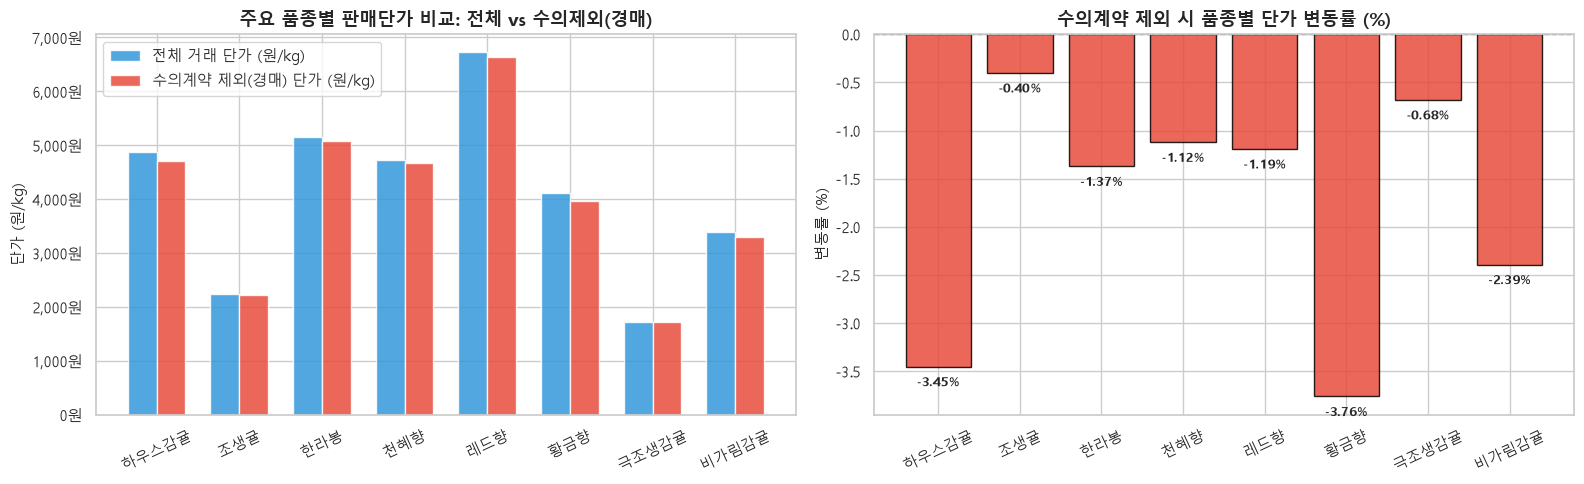

In [7]:
# 4-2) 주요 품종별 수의계약 제외 전/후 판매가격(kg당 단가) 변동 상세 비교
target_vars = ['하우스감귤', '조생귤', '한라봉', '천혜향', '레드향', '황금향', '극조생감귤', '비가림감귤']
var_diff_list = []

for var in target_vars:
    v_all = df[df['variety'] == var]
    v_auc = df[(df['variety'] == var) & (df['trd_type'] != '수의계약')]
    v_neg = df[(df['variety'] == var) & (df['trd_type'] == '수의계약')]
    
    p_all = v_all['total_price'].sum() / (v_all['volume_kg'].sum() + 1e-8)
    p_auc = v_auc['total_price'].sum() / (v_auc['volume_kg'].sum() + 1e-8)
    p_neg = v_neg['total_price'].sum() / (v_neg['volume_kg'].sum() + 1e-8) if len(v_neg) > 0 else np.nan
    
    diff = p_auc - p_all
    pct = (diff / p_all) * 100
    neg_share = (len(v_neg) / len(v_all)) * 100
    
    var_diff_list.append({
        '품종': var,
        '전체 거래건수': len(v_all),
        '수의계약 건수': len(v_neg),
        '수의 비중(%)': round(neg_share, 1),
        '전체 평균단가(원)': round(p_all, 1),
        '수의계약 단가(원)': round(p_neg, 1) if not np.isnan(p_neg) else 0,
        '수의제외(경매) 단가(원)': round(p_auc, 1),
        '단가변동액(원)': round(diff, 1),
        '변동률(%)': round(pct, 2)
    })

var_diff_df = pd.DataFrame(var_diff_list)
display(var_diff_df)

# 주요 품종별 수의계약 제외에 따른 단가 변동 시각화
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

x_idx = np.arange(len(var_diff_df))
w = 0.35
ax1.bar(x_idx - w/2, var_diff_df['전체 평균단가(원)'], width=w, label='전체 거래 단가 (원/kg)', color='#3498db', alpha=0.85)
ax1.bar(x_idx + w/2, var_diff_df['수의제외(경매) 단가(원)'], width=w, label='수의계약 제외(경매) 단가 (원/kg)', color='#e74c3c', alpha=0.85)
ax1.set_xticks(x_idx)
ax1.set_xticklabels(var_diff_df['품종'], rotation=25)
ax1.set_title("주요 품종별 판매단가 비교: 전체 vs 수의제외(경매)", fontsize=13, fontweight='bold')
ax1.set_ylabel("단가 (원/kg)", fontsize=11)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax1.legend()

colors_bar = ['#e74c3c' if v < 0 else '#2ecc71' for v in var_diff_df['변동률(%)']]
bars = ax2.bar(var_diff_df['품종'], var_diff_df['변동률(%)'], color=colors_bar, alpha=0.85, edgecolor='black')
ax2.axhline(0, color='gray', linestyle='--', linewidth=1)
ax2.set_title("수의계약 제외 시 품종별 단가 변동률 (%)", fontsize=13, fontweight='bold')
ax2.set_ylabel("변동률 (%)", fontsize=11)
ax2.tick_params(axis='x', rotation=25)
for bar in bars:
    h = bar.get_height()
    va_pos = 'bottom' if h >= 0 else 'top'
    y_off = 0.1 if h >= 0 else -0.1
    ax2.annotate(f"{h:+.2f}%", (bar.get_x() + bar.get_width() / 2, h + y_off),
                 ha='center', va=va_pos, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

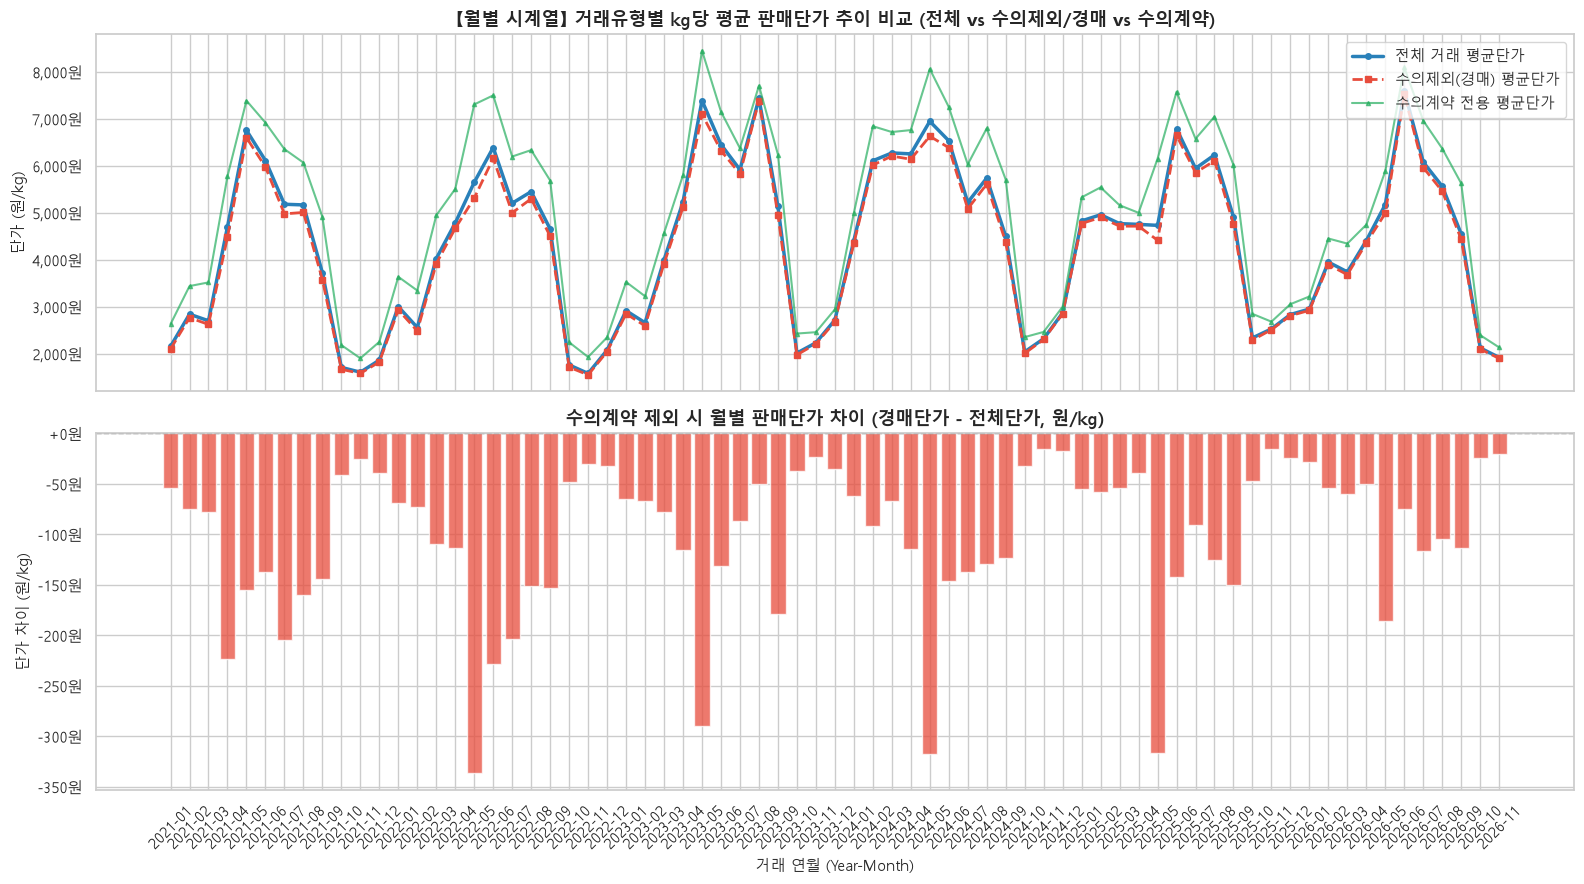


순수 경매(수의제외) 분석 데이터셋 생성 완료: 1,479,916 건


In [8]:
# 4-3) 월별 시계열 단가 추이 비교: 전체 거래 vs 수의계약 제외(경매)
monthly_all = df.groupby('year_month').agg(rev=('total_price', 'sum'), kg=('volume_kg', 'sum')).reset_index()
monthly_all['price_all'] = monthly_all['rev'] / (monthly_all['kg'] + 1e-8)

monthly_auc = df[df['trd_type'] != '수의계약'].groupby('year_month').agg(rev=('total_price', 'sum'), kg=('volume_kg', 'sum')).reset_index()
monthly_auc['price_auc'] = monthly_auc['rev'] / (monthly_auc['kg'] + 1e-8)

monthly_neg = df[df['trd_type'] == '수의계약'].groupby('year_month').agg(rev=('total_price', 'sum'), kg=('volume_kg', 'sum')).reset_index()
monthly_neg['price_neg'] = monthly_neg['rev'] / (monthly_neg['kg'] + 1e-8)

m_merged = monthly_all[['year_month', 'price_all']].merge(monthly_auc[['year_month', 'price_auc']], on='year_month')
m_merged = m_merged.merge(monthly_neg[['year_month', 'price_neg']], on='year_month', how='left')
m_merged['diff'] = m_merged['price_auc'] - m_merged['price_all']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

ax1.plot(m_merged['year_month'], m_merged['price_all'], label='전체 거래 평균단가', color='#2980b9', linewidth=2.5, marker='o', markersize=4)
ax1.plot(m_merged['year_month'], m_merged['price_auc'], label='수의제외(경매) 평균단가', color='#e74c3c', linewidth=2, linestyle='--', marker='s', markersize=4)
ax1.plot(m_merged['year_month'], m_merged['price_neg'], label='수의계약 전용 평균단가', color='#27ae60', linewidth=1.5, alpha=0.7, marker='^', markersize=3)
ax1.set_title("【월별 시계열】 거래유형별 kg당 평균 판매단가 추이 비교 (전체 vs 수의제외/경매 vs 수의계약)", fontsize=13, fontweight='bold')
ax1.set_ylabel("단가 (원/kg)", fontsize=11)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax1.legend(loc='upper right', frameon=True)

ax2.bar(m_merged['year_month'], m_merged['diff'], color=np.where(m_merged['diff'] < 0, '#e74c3c', '#2980b9'), alpha=0.75)
ax2.axhline(0, color='gray', linestyle='--', linewidth=1)
ax2.set_title("수의계약 제외 시 월별 판매단가 차이 (경매단가 - 전체단가, 원/kg)", fontsize=13, fontweight='bold')
ax2.set_xlabel("거래 연월 (Year-Month)", fontsize=11)
ax2.set_ylabel("단가 차이 (원/kg)", fontsize=11)
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):+,}원"))
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

df_auction = df[df['trd_type'] != '수의계약'].copy().reset_index(drop=True)
print(f"\n순수 경매(수의제외) 분석 데이터셋 생성 완료: {len(df_auction):,} 건")

## 5. [날짜별] 판매수량 및 판매가격 분석 및 시각화
- **일별 전체 물량 & kg당 평균 단가 시계열 추이** (2축 Dual-Axis 차트, 7일 이동평균 추세선)
- **월별 누적 판매물량 및 월평균 단가 추이** (계절성 및 출하 사이클 파악)
- **연도별/월별 물량 히트맵**

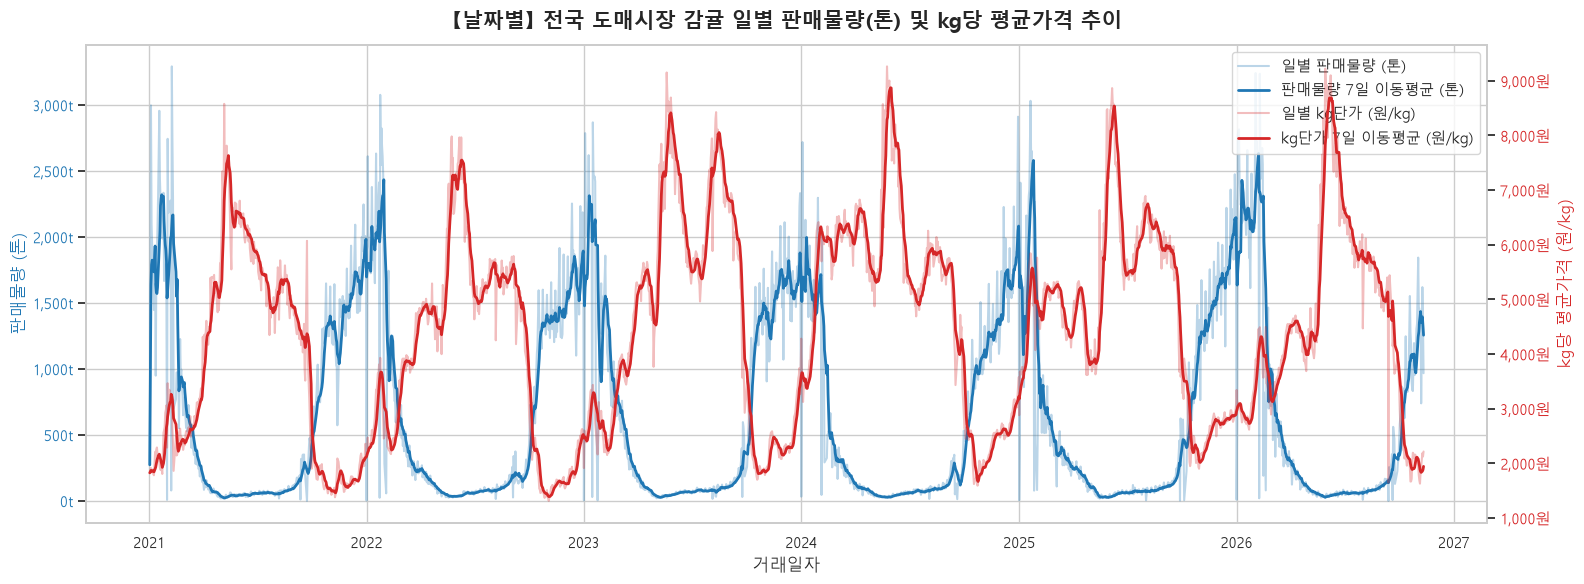

In [9]:
# 1) 일별 집계
daily_agg = df.groupby('date').agg(
    daily_volume_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    daily_boxes=('box_qty', 'sum'),
    daily_total_price=('total_price', 'sum'),
    daily_volume_kg=('volume_kg', 'sum')
).reset_index()
daily_agg['daily_avg_price_kg'] = daily_agg['daily_total_price'] / (daily_agg['daily_volume_kg'] + 1e-8)

daily_agg['vol_ton_ma7'] = daily_agg['daily_volume_ton'].rolling(7, min_periods=1).mean()
daily_agg['price_kg_ma7'] = daily_agg['daily_avg_price_kg'].rolling(7, min_periods=1).mean()

fig, ax1 = plt.subplots(figsize=(16, 6))

color_vol = '#1f77b4'
color_price = '#d62728'

ax1.set_title("【날짜별】 전국 도매시장 감귤 일별 판매물량(톤) 및 kg당 평균가격 추이", fontsize=15, pad=12, fontweight='bold')
ax1.plot(daily_agg['date'], daily_agg['daily_volume_ton'], color=color_vol, alpha=0.3, label='일별 판매물량 (톤)')
ax1.plot(daily_agg['date'], daily_agg['vol_ton_ma7'], color=color_vol, linewidth=2, label='판매물량 7일 이동평균 (톤)')
ax1.set_xlabel('거래일자', fontsize=12)
ax1.set_ylabel('판매물량 (톤)', color=color_vol, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_vol)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))

ax2 = ax1.twinx()
ax2.plot(daily_agg['date'], daily_agg['daily_avg_price_kg'], color=color_price, alpha=0.3, label='일별 kg단가 (원/kg)')
ax2.plot(daily_agg['date'], daily_agg['price_kg_ma7'], color=color_price, linewidth=2, label='kg단가 7일 이동평균 (원/kg)')
ax2.set_ylabel('kg당 평균가격 (원/kg)', color=color_price, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_price)
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax2.grid(False)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

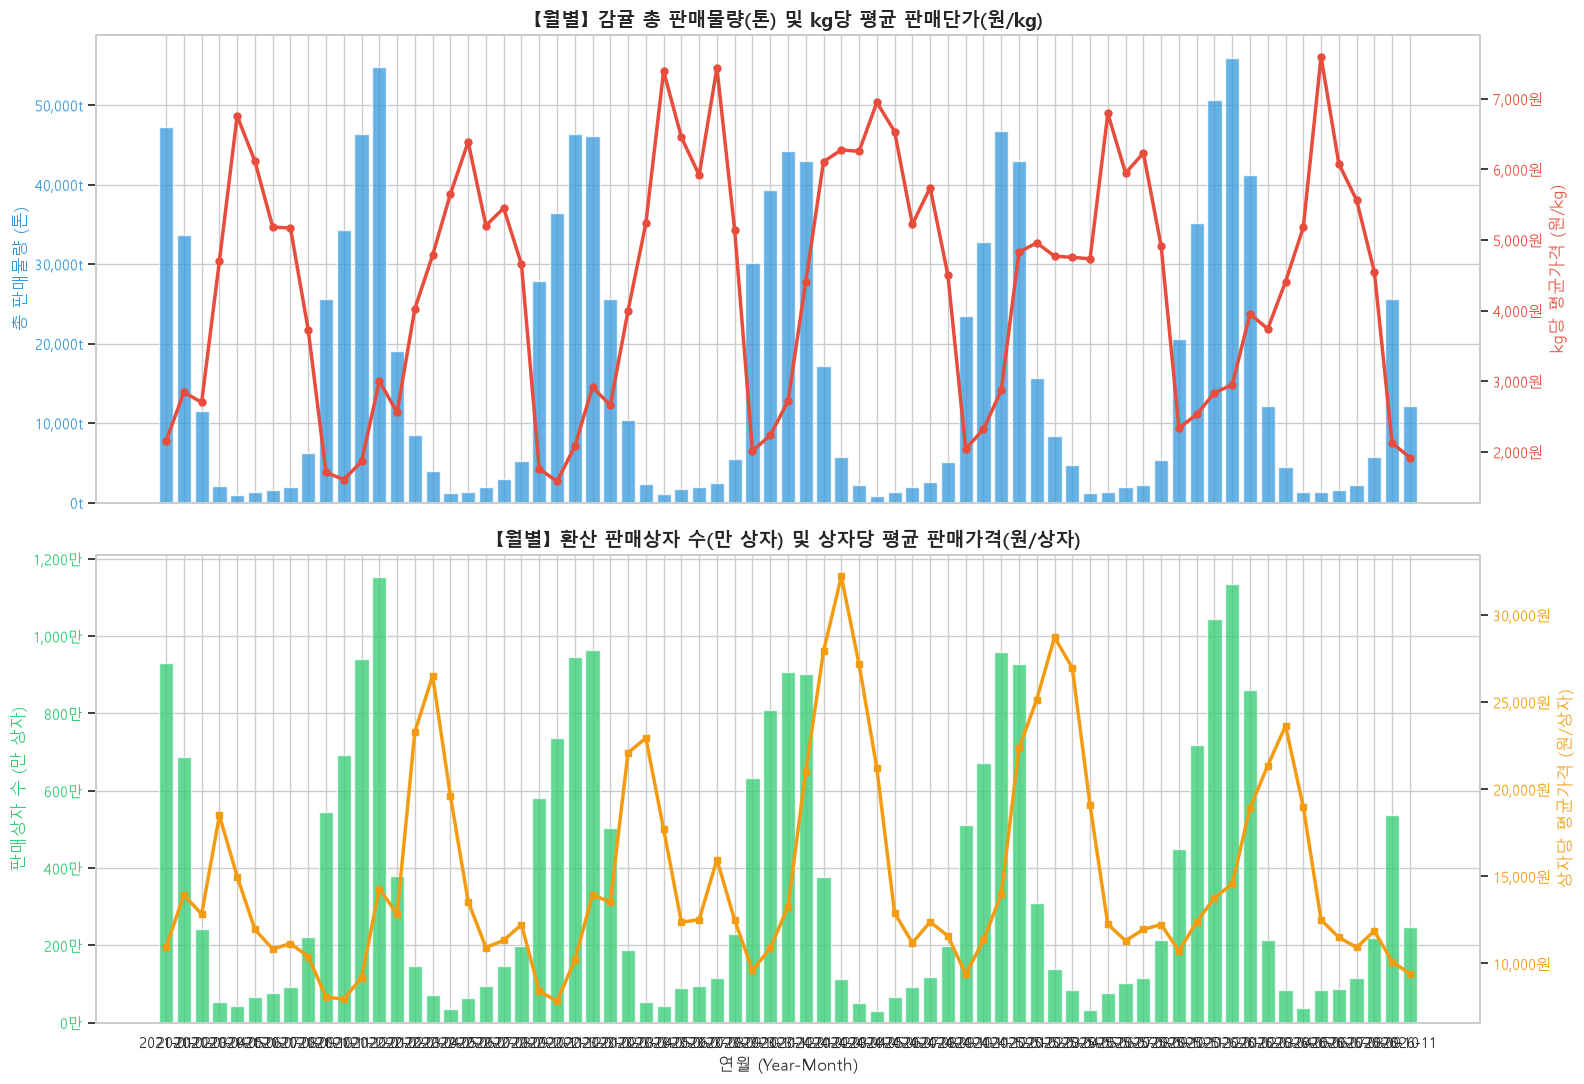

In [10]:
# 2) 월별 집계 및 복합 차트 (월별 판매수량 막대 + 월별 평균단가 꺾은선)
monthly_agg = df.groupby('year_month').agg(
    total_volume_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    total_boxes=('box_qty', 'sum'),
    total_price=('total_price', 'sum'),
    total_volume_kg=('volume_kg', 'sum')
).reset_index()
monthly_agg['avg_unit_price_kg'] = monthly_agg['total_price'] / (monthly_agg['total_volume_kg'] + 1e-8)
monthly_agg['avg_box_price'] = monthly_agg['total_price'] / (monthly_agg['total_boxes'] + 1e-8)

fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(16, 11), sharex=True)

color_bar = '#3498db'
color_line = '#e74c3c'

ax1.bar(monthly_agg['year_month'], monthly_agg['total_volume_ton'], color=color_bar, alpha=0.75, label='월별 총 판매물량 (톤)')
ax1.set_ylabel('총 판매물량 (톤)', color=color_bar, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_bar)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
ax1.set_title("【월별】 감귤 총 판매물량(톤) 및 kg당 평균 판매단가(원/kg)", fontsize=14, fontweight='bold')

ax2 = ax1.twinx()
ax2.plot(monthly_agg['year_month'], monthly_agg['avg_unit_price_kg'], color=color_line, marker='o', linewidth=2.5, markersize=5, label='월평균 kg당 단가 (원/kg)')
ax2.set_ylabel('kg당 평균가격 (원/kg)', color=color_line, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_line)
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax2.grid(False)

color_box_bar = '#2ecc71'
color_box_line = '#f39c12'

ax3.bar(monthly_agg['year_month'], monthly_agg['total_boxes'] / 10000, color=color_box_bar, alpha=0.75, label='월별 환산 판매상자 수 (만 상자)')
ax3.set_ylabel('판매상자 수 (만 상자)', color=color_box_bar, fontsize=12)
ax3.tick_params(axis='y', labelcolor=color_box_bar)
ax3.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}만"))
ax3.set_title("【월별】 환산 판매상자 수(만 상자) 및 상자당 평균 판매가격(원/상자)", fontsize=14, fontweight='bold')
ax3.set_xlabel('연월 (Year-Month)', fontsize=12)
plt.xticks(rotation=45)

ax4 = ax3.twinx()
ax4.plot(monthly_agg['year_month'], monthly_agg['avg_box_price'], color=color_box_line, marker='s', linewidth=2.5, markersize=5, label='월평균 상자당 가격 (원/상자)')
ax4.set_ylabel('상자당 평균가격 (원/상자)', color=color_box_line, fontsize=12)
ax4.tick_params(axis='y', labelcolor=color_box_line)
ax4.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax4.grid(False)

plt.tight_layout()
plt.show()

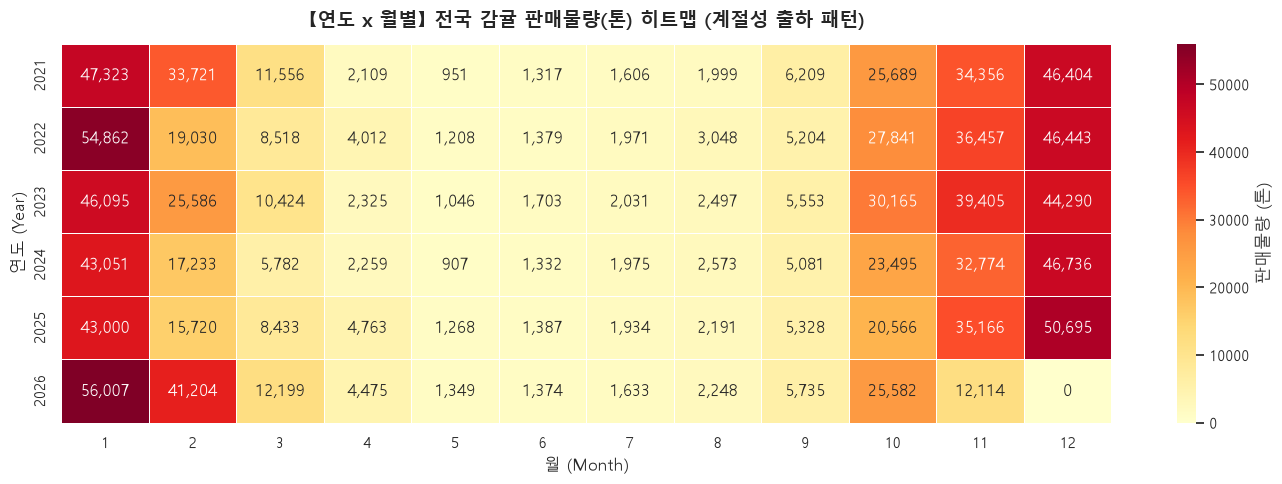

In [11]:
# 3) 연도별 x 월별 판매물량 히트맵 (출하 계절성 패턴 시각화)
pivot_vol = df.pivot_table(index='year', columns='month', values='volume_kg', aggfunc=lambda x: x.sum() / 1000.0).fillna(0)

plt.figure(figsize=(14, 5))
sns.heatmap(pivot_vol, cmap='YlOrRd', annot=True, fmt=',.0f', cbar_kws={'label': '판매물량 (톤)'}, linewidths=0.5)
plt.title("【연도 x 월별】 전국 감귤 판매물량(톤) 히트맵 (계절성 출하 패턴)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("월 (Month)", fontsize=12)
plt.ylabel("연도 (Year)", fontsize=12)
plt.tight_layout()
plt.show()

## 6. [등급별] 판매수량 및 판매가격 분석 및 시각화
- 등급(`특`, `상`, `중`, `하`, `등외`, `무등급/미지정`)별 총 판매수량(kg 및 상자수)
- 등급별 평균 판매가격(kg당 단가 및 상자당 가격) 비교
- 등급별 판매가격 분포(Boxplot) 시각화

In [12]:
# 1) 등급별 판매수량 및 평균단가 집계
grade_order = ['특', '상', '중', '하', '등외', '무등급/미지정']
avail_grades = [g for g in grade_order if g in df['grade'].values]
other_grades = [g for g in df['grade'].unique() if g not in grade_order]
all_grade_order = avail_grades + other_grades

grade_agg = df.groupby('grade').agg(
    total_volume_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    total_boxes=('box_qty', 'sum'),
    total_price=('total_price', 'sum'),
    total_volume_kg=('volume_kg', 'sum'),
    box_price_mean=('box_price', 'mean'),
    count=('volume_kg', 'count')
).reindex(all_grade_order).dropna(subset=['count']).reset_index()

grade_agg['avg_unit_price_kg'] = grade_agg['total_price'] / (grade_agg['total_volume_kg'] + 1e-8)
grade_agg['share_pct'] = (grade_agg['total_volume_kg'] / grade_agg['total_volume_kg'].sum()) * 100

display(grade_agg[['grade', 'count', 'total_volume_ton', 'share_pct', 'total_boxes', 'avg_unit_price_kg', 'box_price_mean']]
        .rename(columns={
            'grade': '등급',
            'count': '거래건수',
            'total_volume_ton': '총 판매물량(톤)',
            'share_pct': '물량 비중(%)',
            'total_boxes': '환산상자수',
            'avg_unit_price_kg': 'kg당 평균단가(원)',
            'box_price_mean': '상자당 평균가격(원)'
        }))

,등급,거래건수,총 판매물량(톤),물량 비중(%),환산상자수,kg당 평균단가(원),상자당 평균가격(원)
0,특,1307872,806794.03415,68.844799,1.792427e+08,3150.397567,19724.874013
1,상,76856,68956.82613,5.884177,1.514934e+07,2819.101113,16728.914701
2,중,91030,50850.84185,4.339169,1.073959e+07,2539.579748,12512.579915
3,하,32412,15379.36267,1.312341,3.197971e+06,2441.176887,14075.689962
4,등외,47664,55166.68639,4.707446,1.144639e+07,2828.136599,17430.903668
5,무등급/미지정,126904,158284.46868,13.506623,3.366458e+07,2602.940347,16837.982755
6,8등,4383,673.46127,0.057467,1.545700e+05,4769.563690,21183.496554
7,7등,8539,2006.24137,0.171195,5.022070e+05,3572.492332,17566.565555
8,6등,8128,4365.40365,0.372506,8.734390e+05,2109.009541,16270.246714
9,5등,17122,6697.32695,0.571492,1.367075e+06,2394.191233,15088.413914


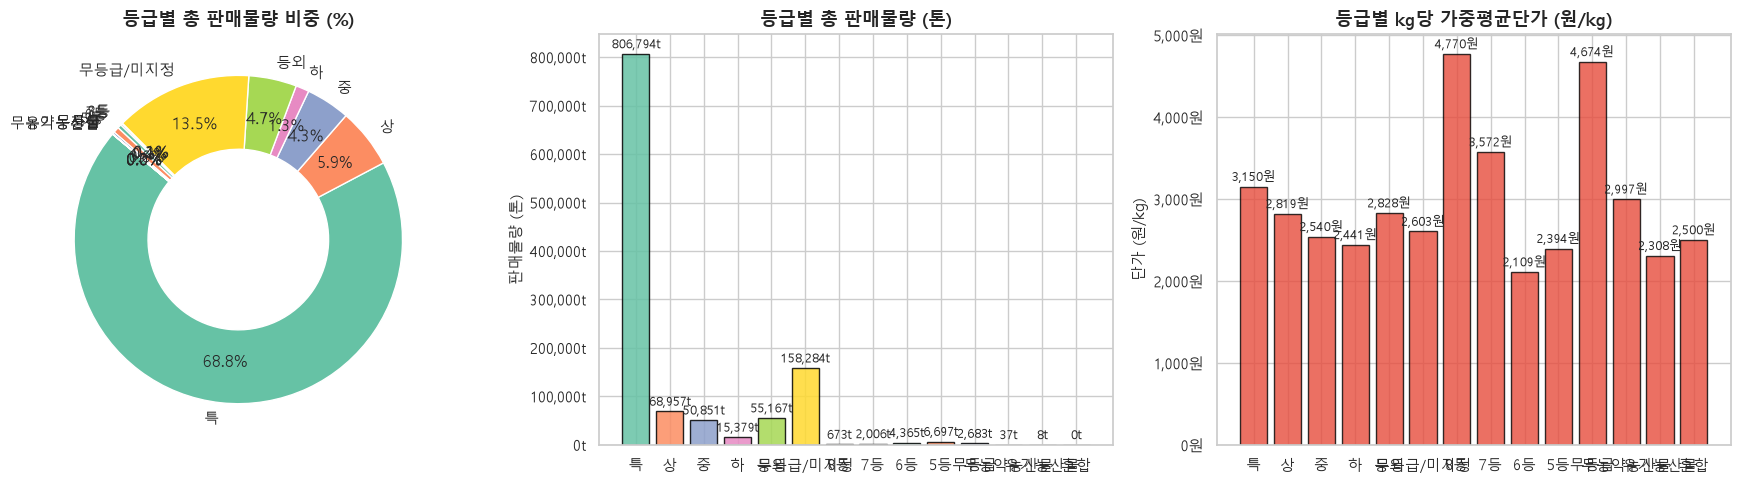

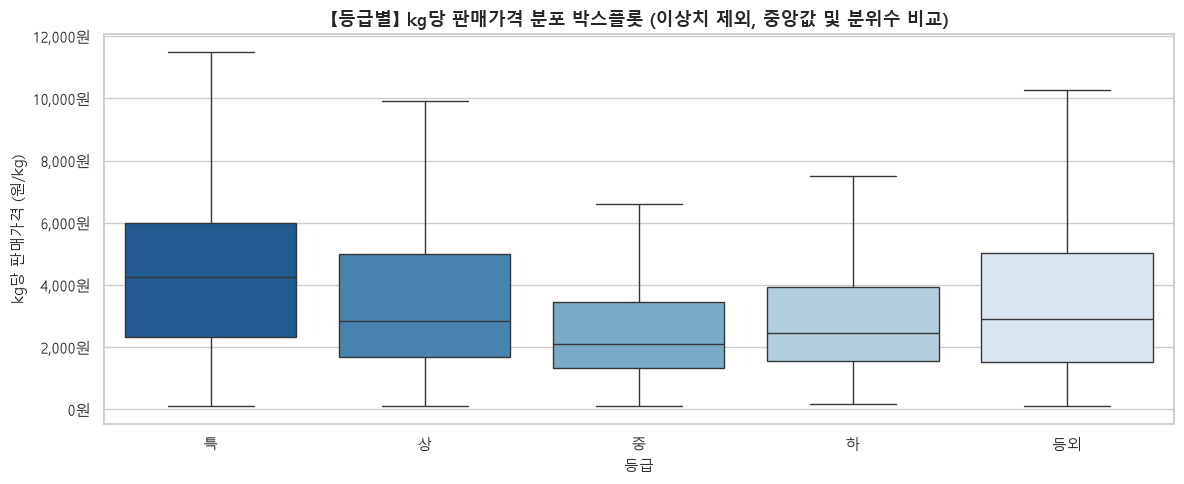

In [13]:
# 2) 등급별 물량 비중 및 평균 단가 비교 그래프
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

colors_grade = sns.color_palette('Set2', len(grade_agg))
axes[0].pie(grade_agg['total_volume_ton'], labels=grade_agg['grade'], autopct='%1.1f%%',
            startangle=140, colors=colors_grade, pctdistance=0.75,
            wedgeprops=dict(width=0.45, edgecolor='w'))
axes[0].set_title("등급별 총 판매물량 비중 (%)", fontsize=13, fontweight='bold')

bars = axes[1].bar(grade_agg['grade'], grade_agg['total_volume_ton'], color=colors_grade, edgecolor='black', alpha=0.85)
axes[1].set_title("등급별 총 판매물량 (톤)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("판매물량 (톤)", fontsize=11)
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
for bar in bars:
    h = bar.get_height()
    axes[1].annotate(f"{h:,.0f}t", (bar.get_x() + bar.get_width() / 2, h),
                     textcoords="offset points", xytext=(0, 4), ha='center', fontsize=9)

bars_p = axes[2].bar(grade_agg['grade'], grade_agg['avg_unit_price_kg'], color='#e74c3c', edgecolor='black', alpha=0.8)
axes[2].set_title("등급별 kg당 가중평균단가 (원/kg)", fontsize=13, fontweight='bold')
axes[2].set_ylabel("단가 (원/kg)", fontsize=11)
axes[2].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
for bar in bars_p:
    h = bar.get_height()
    axes[2].annotate(f"{h:,.0f}원", (bar.get_x() + bar.get_width() / 2, h),
                     textcoords="offset points", xytext=(0, 4), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

main_grades = [g for g in ['특', '상', '중', '하', '등외'] if g in df['grade'].values]
sub_grade_df = df[df['grade'].isin(main_grades)].copy()

plt.figure(figsize=(12, 5))
sns.boxplot(data=sub_grade_df, x='grade', y='unit_price_kg', order=main_grades, palette='Blues_r', showfliers=False)
plt.title("【등급별】 kg당 판매가격 분포 박스플롯 (이상치 제외, 중앙값 및 분위수 비교)", fontsize=13, fontweight='bold')
plt.xlabel("등급", fontsize=11)
plt.ylabel("kg당 판매가격 (원/kg)", fontsize=11)
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
plt.tight_layout()
plt.show()

## 7. [종류별 (품종별)] 판매수량 및 판매가격 분석 및 시각화
- 감귤 종류(하우스감귤, 조생귤, 한라봉, 천혜향, 레드향, 황금향, 극조생감귤, 비가림감귤 등)별 판매수량 및 순위
- 품종별 kg당 평균 판매가격 비교 (만감류 vs 온주밀감 프리미엄 비교)
- 주요 4대 대표 품종(하우스감귤, 조생귤, 한라봉, 천혜향)의 월별 판매물량 및 단가 추이

In [14]:
# 1) 품종별 집계
variety_agg = df.groupby('variety').agg(
    total_volume_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    total_boxes=('box_qty', 'sum'),
    total_price=('total_price', 'sum'),
    total_volume_kg=('volume_kg', 'sum'),
    box_price_mean=('box_price', 'mean'),
    count=('volume_kg', 'count')
).reset_index()

variety_agg['avg_unit_price_kg'] = variety_agg['total_price'] / (variety_agg['total_volume_kg'] + 1e-8)
variety_agg['share_pct'] = (variety_agg['total_volume_kg'] / variety_agg['total_volume_kg'].sum()) * 100

variety_agg_vol = variety_agg.sort_values('total_volume_ton', ascending=False).reset_index(drop=True)

display(variety_agg_vol[['variety', 'count', 'total_volume_ton', 'share_pct', 'total_boxes', 'avg_unit_price_kg', 'box_price_mean']]
        .rename(columns={
            'variety': '품종(종류)',
            'count': '거래건수',
            'total_volume_ton': '총 판매물량(톤)',
            'share_pct': '물량 비중(%)',
            'total_boxes': '환산상자수',
            'avg_unit_price_kg': 'kg당 평균단가(원)',
            'box_price_mean': '상자당 평균가격(원)'
        }))

,품종(종류),거래건수,총 판매물량(톤),물량 비중(%),환산상자수,kg당 평균단가(원),상자당 평균가격(원)
0,조생귤,316478,500214.22010,42.683939,9.942473e+07,2233.197870,10764.122022
1,기타,305270,212263.90894,18.112759,4.440435e+07,2719.168804,19010.764910
2,한라봉,328214,107411.90290,9.165599,2.141369e+07,5143.985822,26662.380688
3,극조생감귤,92528,97957.61731,8.358853,1.939160e+07,1720.572268,8029.063964
4,하우스감귤,322086,89987.56901,7.678758,3.569970e+07,4869.481118,18673.942212
5,비가림감귤,63145,36655.72555,3.127881,8.029755e+06,3380.764866,15139.422961
6,천혜향,107971,34270.77832,2.924371,7.702216e+06,4729.028870,22357.191790
7,레드향,90212,27305.43612,2.330009,6.634663e+06,6721.535704,28030.625968
8,감귤(일반),10123,24069.72094,2.053901,5.107165e+06,2478.266100,12983.550942
9,타이벡감귤,19696,16247.42540,1.386414,3.308314e+06,3127.175261,14447.200252


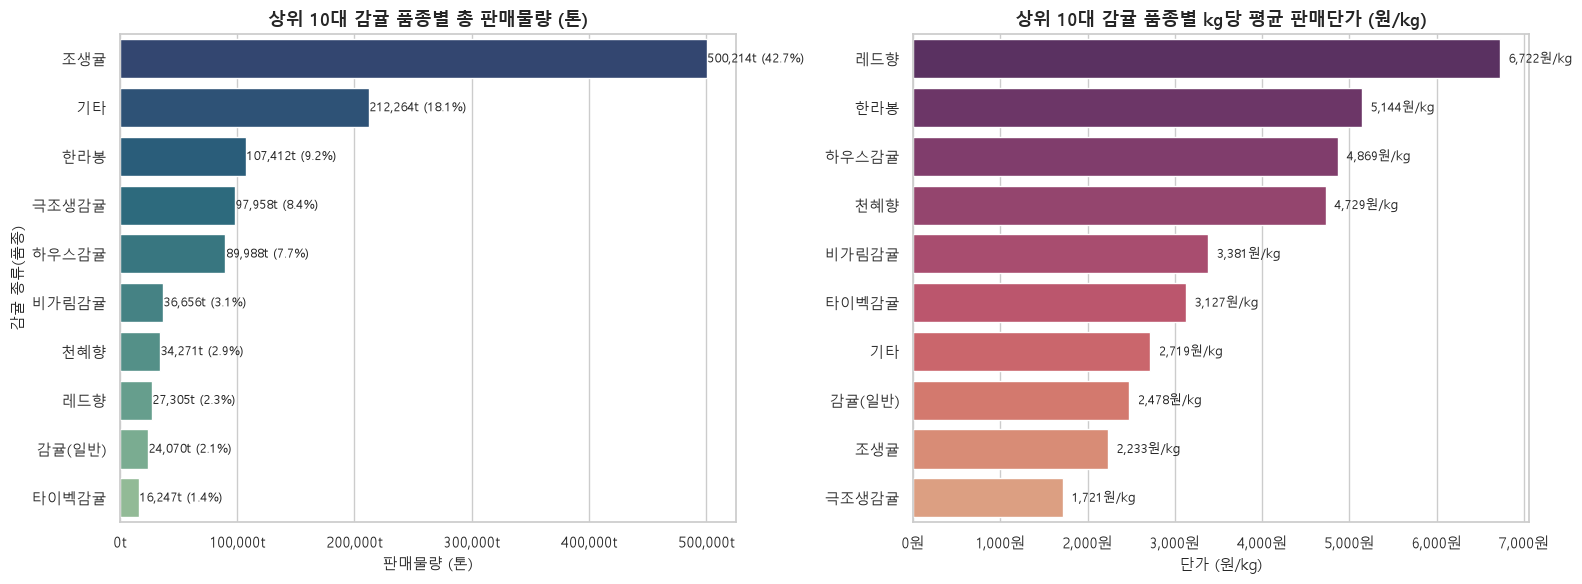

In [15]:
# 2) 품종별 판매물량 및 평균 판매가격 비교 차트 (상위 10대 품종)
top_varieties_df = variety_agg_vol.head(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=top_varieties_df, y='variety', x='total_volume_ton', ax=ax1, palette='crest_r')
ax1.set_title("상위 10대 감귤 품종별 총 판매물량 (톤)", fontsize=13, fontweight='bold')
ax1.set_xlabel("판매물량 (톤)", fontsize=11)
ax1.set_ylabel("감귤 종류(품종)", fontsize=11)
ax1.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
for i, v in enumerate(top_varieties_df['total_volume_ton']):
    ax1.text(v + 500, i, f"{v:,.0f}t ({top_varieties_df['share_pct'].iloc[i]:.1f}%)", va='center', fontsize=9)

top_varieties_price_df = top_varieties_df.sort_values('avg_unit_price_kg', ascending=False)
sns.barplot(data=top_varieties_price_df, y='variety', x='avg_unit_price_kg', ax=ax2, palette='flare_r')
ax2.set_title("상위 10대 감귤 품종별 kg당 평균 판매단가 (원/kg)", fontsize=13, fontweight='bold')
ax2.set_xlabel("단가 (원/kg)", fontsize=11)
ax2.set_ylabel("", fontsize=11)
ax2.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
for i, v in enumerate(top_varieties_price_df['avg_unit_price_kg']):
    ax2.text(v + 100, i, f"{v:,.0f}원/kg", va='center', fontsize=9)

plt.tight_layout()
plt.show()

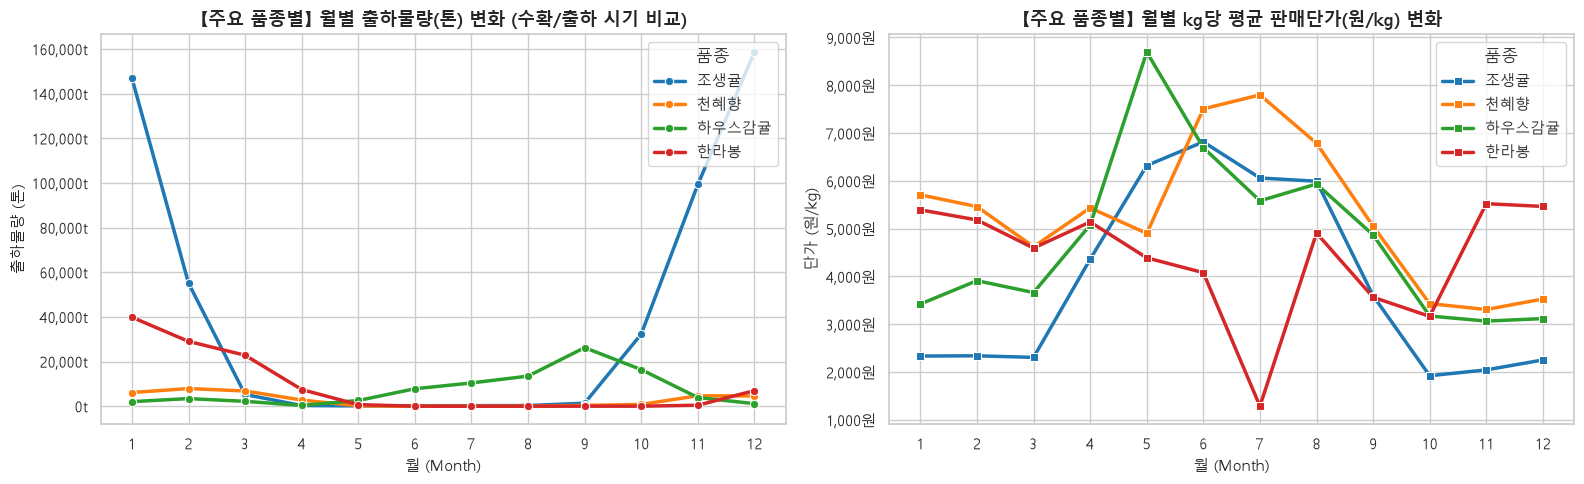

In [16]:
# 3) 주요 4대 대표 품종(하우스감귤, 조생귤, 한라봉, 천혜향)의 월별 물량 및 단가 동적 비교
core_vars = ['하우스감귤', '조생귤', '한라봉', '천혜향']
core_df = df[df['variety'].isin(core_vars)].copy()

var_month_agg = core_df.groupby(['month', 'variety']).agg(
    vol_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    total_price=('total_price', 'sum'),
    total_kg=('volume_kg', 'sum')
).reset_index()
var_month_agg['avg_price_kg'] = var_month_agg['total_price'] / (var_month_agg['total_kg'] + 1e-8)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

sns.lineplot(data=var_month_agg, x='month', y='vol_ton', hue='variety', marker='o', linewidth=2.5, ax=ax1, palette='tab10')
ax1.set_title("【주요 품종별】 월별 출하물량(톤) 변화 (수확/출하 시기 비교)", fontsize=13, fontweight='bold')
ax1.set_xlabel("월 (Month)", fontsize=11)
ax1.set_ylabel("출하물량 (톤)", fontsize=11)
ax1.set_xticks(range(1, 13))
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
ax1.legend(title='품종', loc='upper right')

sns.lineplot(data=var_month_agg, x='month', y='avg_price_kg', hue='variety', marker='s', linewidth=2.5, ax=ax2, palette='tab10')
ax2.set_title("【주요 품종별】 월별 kg당 평균 판매단가(원/kg) 변화", fontsize=13, fontweight='bold')
ax2.set_xlabel("월 (Month)", fontsize=11)
ax2.set_ylabel("단가 (원/kg)", fontsize=11)
ax2.set_xticks(range(1, 13))
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax2.legend(title='품종', loc='upper right')

plt.tight_layout()
plt.show()

## 8. [크기별] 판매수량 및 판매가격 분석 (품종별 세부 분류 포함)
- **크기 규격 정렬 기준**: 사용자가 지정한 표준 크기 순서 (`50내` -> `45내` -> `40내` -> `35내` -> `소` -> `중` -> `대` -> `특대`)로 정리하여 분석합니다.
- **8-1) 전체 감귤 크기 규격별 분석**: 지정 크기 규격 순서별 총 판매물량(톤), 물량 비중(%), kg당 평균단가(원/kg)
- **8-2) [품종별 세부 분류]**: 감귤 품종(하우스감귤, 조생귤, 천혜향, 황금향, 레드향)마다 동일한 표준 크기 순서(`50내, 45내, 40내, 35내, 소, 중, 대, 특대`)로 세부 분류하여 판매물량과 판매단가를 비교 분석합니다.

,크기 규격,거래건수,총 판매물량(톤),물량 비중(%),환산상자수,kg당 평균단가(원),상자당 평균가격(원)
0,50내,79848,29918.16324,12.573733,5755046.0,3905.793355,22852.225892
1,45내,47340,9109.10300,3.828291,1756564.0,5054.719136,27484.973266
2,40내,78595,28672.82752,12.050355,5723019.0,4130.268215,23291.709861
3,35내,46592,8774.23620,3.687556,1917322.0,4777.756023,23608.090408
4,소,36781,61346.28564,25.782058,12330265.0,2702.179436,13771.840394
5,중,25246,34065.58300,14.316773,6839490.0,2464.253081,12883.914917
6,대,28040,29569.98080,12.427402,5902558.0,2028.534080,9987.304459
7,특대,41306,36485.58790,15.333831,7288093.0,2096.643861,12201.945465


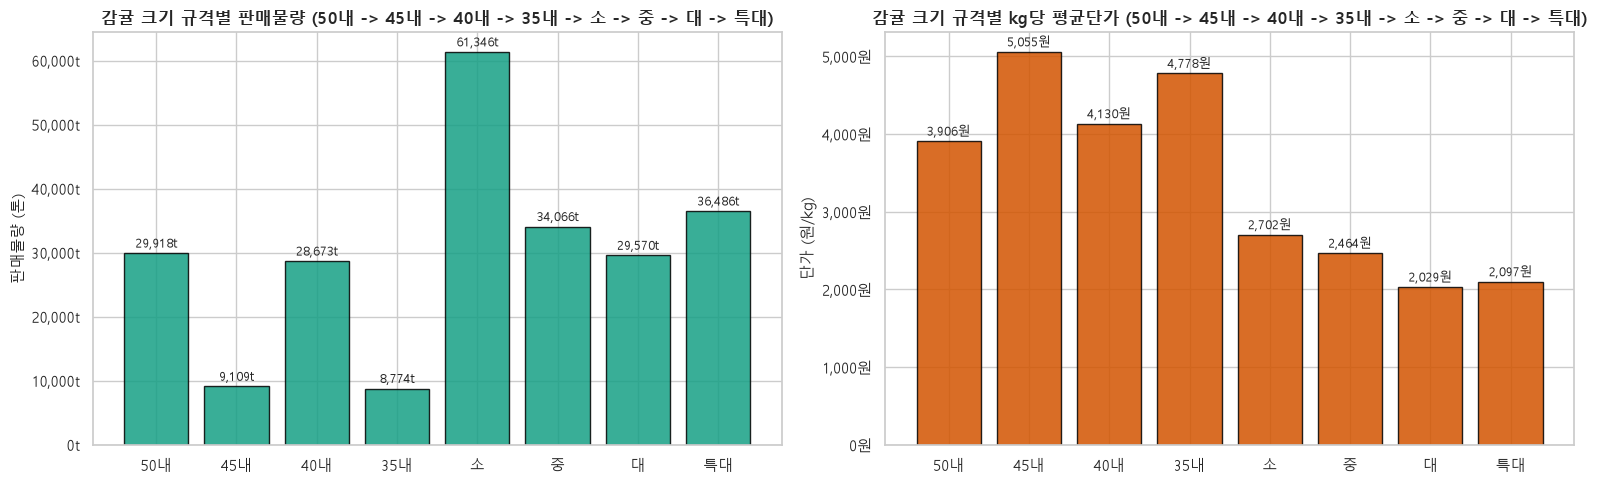

In [17]:
# 8-1) 전체 크기 규격별 집계 (지정 순서: 50내, 45내, 40내, 35내, 소, 중, 대, 특대)
size_order = ['50내', '45내', '40내', '35내', '소', '중', '대', '특대']

size_agg = df[df['size'].isin(size_order)].groupby('size').agg(
    total_volume_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    total_boxes=('box_qty', 'sum'),
    total_price=('total_price', 'sum'),
    total_volume_kg=('volume_kg', 'sum'),
    box_price_mean=('box_price', 'mean'),
    count=('volume_kg', 'count')
).reindex(size_order).reset_index()

size_agg['avg_unit_price_kg'] = size_agg['total_price'] / (size_agg['total_volume_kg'] + 1e-8)
size_agg['share_pct'] = (size_agg['total_volume_kg'] / size_agg['total_volume_kg'].sum()) * 100

display(size_agg[['size', 'count', 'total_volume_ton', 'share_pct', 'total_boxes', 'avg_unit_price_kg', 'box_price_mean']]
        .rename(columns={
            'size': '크기 규격',
            'count': '거래건수',
            'total_volume_ton': '총 판매물량(톤)',
            'share_pct': '물량 비중(%)',
            'total_boxes': '환산상자수',
            'avg_unit_price_kg': 'kg당 평균단가(원)',
            'box_price_mean': '상자당 평균가격(원)'
        }))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
bars1 = ax1.bar(size_agg['size'], size_agg['total_volume_ton'], color='#16a085', edgecolor='black', alpha=0.85)
ax1.set_title("감귤 크기 규격별 판매물량 (50내 -> 45내 -> 40내 -> 35내 -> 소 -> 중 -> 대 -> 특대)", fontsize=12, fontweight='bold')
ax1.set_ylabel("판매물량 (톤)", fontsize=11)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
for bar in bars1:
    h = bar.get_height()
    ax1.annotate(f"{h:,.0f}t", (bar.get_x() + bar.get_width() / 2, h), textcoords="offset points", xytext=(0, 4), ha='center', fontsize=9)

bars2 = ax2.bar(size_agg['size'], size_agg['avg_unit_price_kg'], color='#d35400', edgecolor='black', alpha=0.85)
ax2.set_title("감귤 크기 규격별 kg당 평균단가 (50내 -> 45내 -> 40내 -> 35내 -> 소 -> 중 -> 대 -> 특대)", fontsize=12, fontweight='bold')
ax2.set_ylabel("단가 (원/kg)", fontsize=11)
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
for bar in bars2:
    h = bar.get_height()
    ax2.annotate(f"{h:,.0f}원", (bar.get_x() + bar.get_width() / 2, h), textcoords="offset points", xytext=(0, 4), ha='center', fontsize=9)
plt.tight_layout()
plt.show()

In [18]:
# 8-2) 【품종별 세부 크기 분류】 주요 5대 품종별 크기 규격별 집계 (지정 순서 적용)
target_varieties = ['하우스감귤', '조생귤', '한라봉', '천혜향', '레드향']
size_order = ['50내', '45내', '40내', '35내', '소', '중', '대', '특대']
variety_size_tables = []

for var in target_varieties:
    sub_df = df[(df['variety'] == var) & (df['size'].isin(size_order))]
    agg = sub_df.groupby('size').agg(
        거래건수=('volume_kg', 'count'),
        총판매물량_톤=('volume_kg', lambda x: x.sum() / 1000.0),
        총판매금액_백만원=('total_price', lambda x: x.sum() / 1e6),
        환산상자수=('box_qty', 'sum'),
        total_kg=('volume_kg', 'sum'),
        total_rev=('total_price', 'sum')
    )
    agg['kg당평균단가_원'] = (agg['total_rev'] / (agg['total_kg'] + 1e-8)).round(0)
    agg['물량비중_pct'] = ((agg['total_kg'] / agg['total_kg'].sum()) * 100).round(1)
    
    # 지정 순서대로 정렬 (존재하는 항목만 필터)
    var_size = agg.reindex(size_order).dropna(subset=['거래건수']).reset_index()
    var_size.insert(0, '품종', var)
    variety_size_tables.append(var_size)

variety_size_summary_df = pd.concat(variety_size_tables, ignore_index=True)
display(variety_size_summary_df[['품종', 'size', '거래건수', '총판매물량_톤', '물량비중_pct', 'kg당평균단가_원', '환산상자수']]
        .rename(columns={'size': '크기 규격'}))

,품종,크기 규격,거래건수,총판매물량_톤,물량비중_pct,kg당평균단가_원,환산상자수
0,하우스감귤,50내,23623,5516.88774,18.9,5767.0,1778513.0
1,하우스감귤,45내,25876,3915.57280,13.4,5465.0,1142259.0
2,하우스감귤,40내,33448,7114.68240,24.4,5765.0,2237417.0
3,하우스감귤,35내,27544,4182.66140,14.3,5404.0,1283897.0
4,하우스감귤,소,5280,4344.08930,14.9,4413.0,922725.0
5,하우스감귤,중,2973,1217.59470,4.2,3866.0,275078.0
6,하우스감귤,대,3267,890.52090,3.0,3217.0,189658.0
7,하우스감귤,특대,6209,2021.75100,6.9,4831.0,462290.0
8,조생귤,50내,14843,7828.41200,11.0,2222.0,1537750.0
9,조생귤,45내,298,46.53400,0.1,4272.0,13224.0


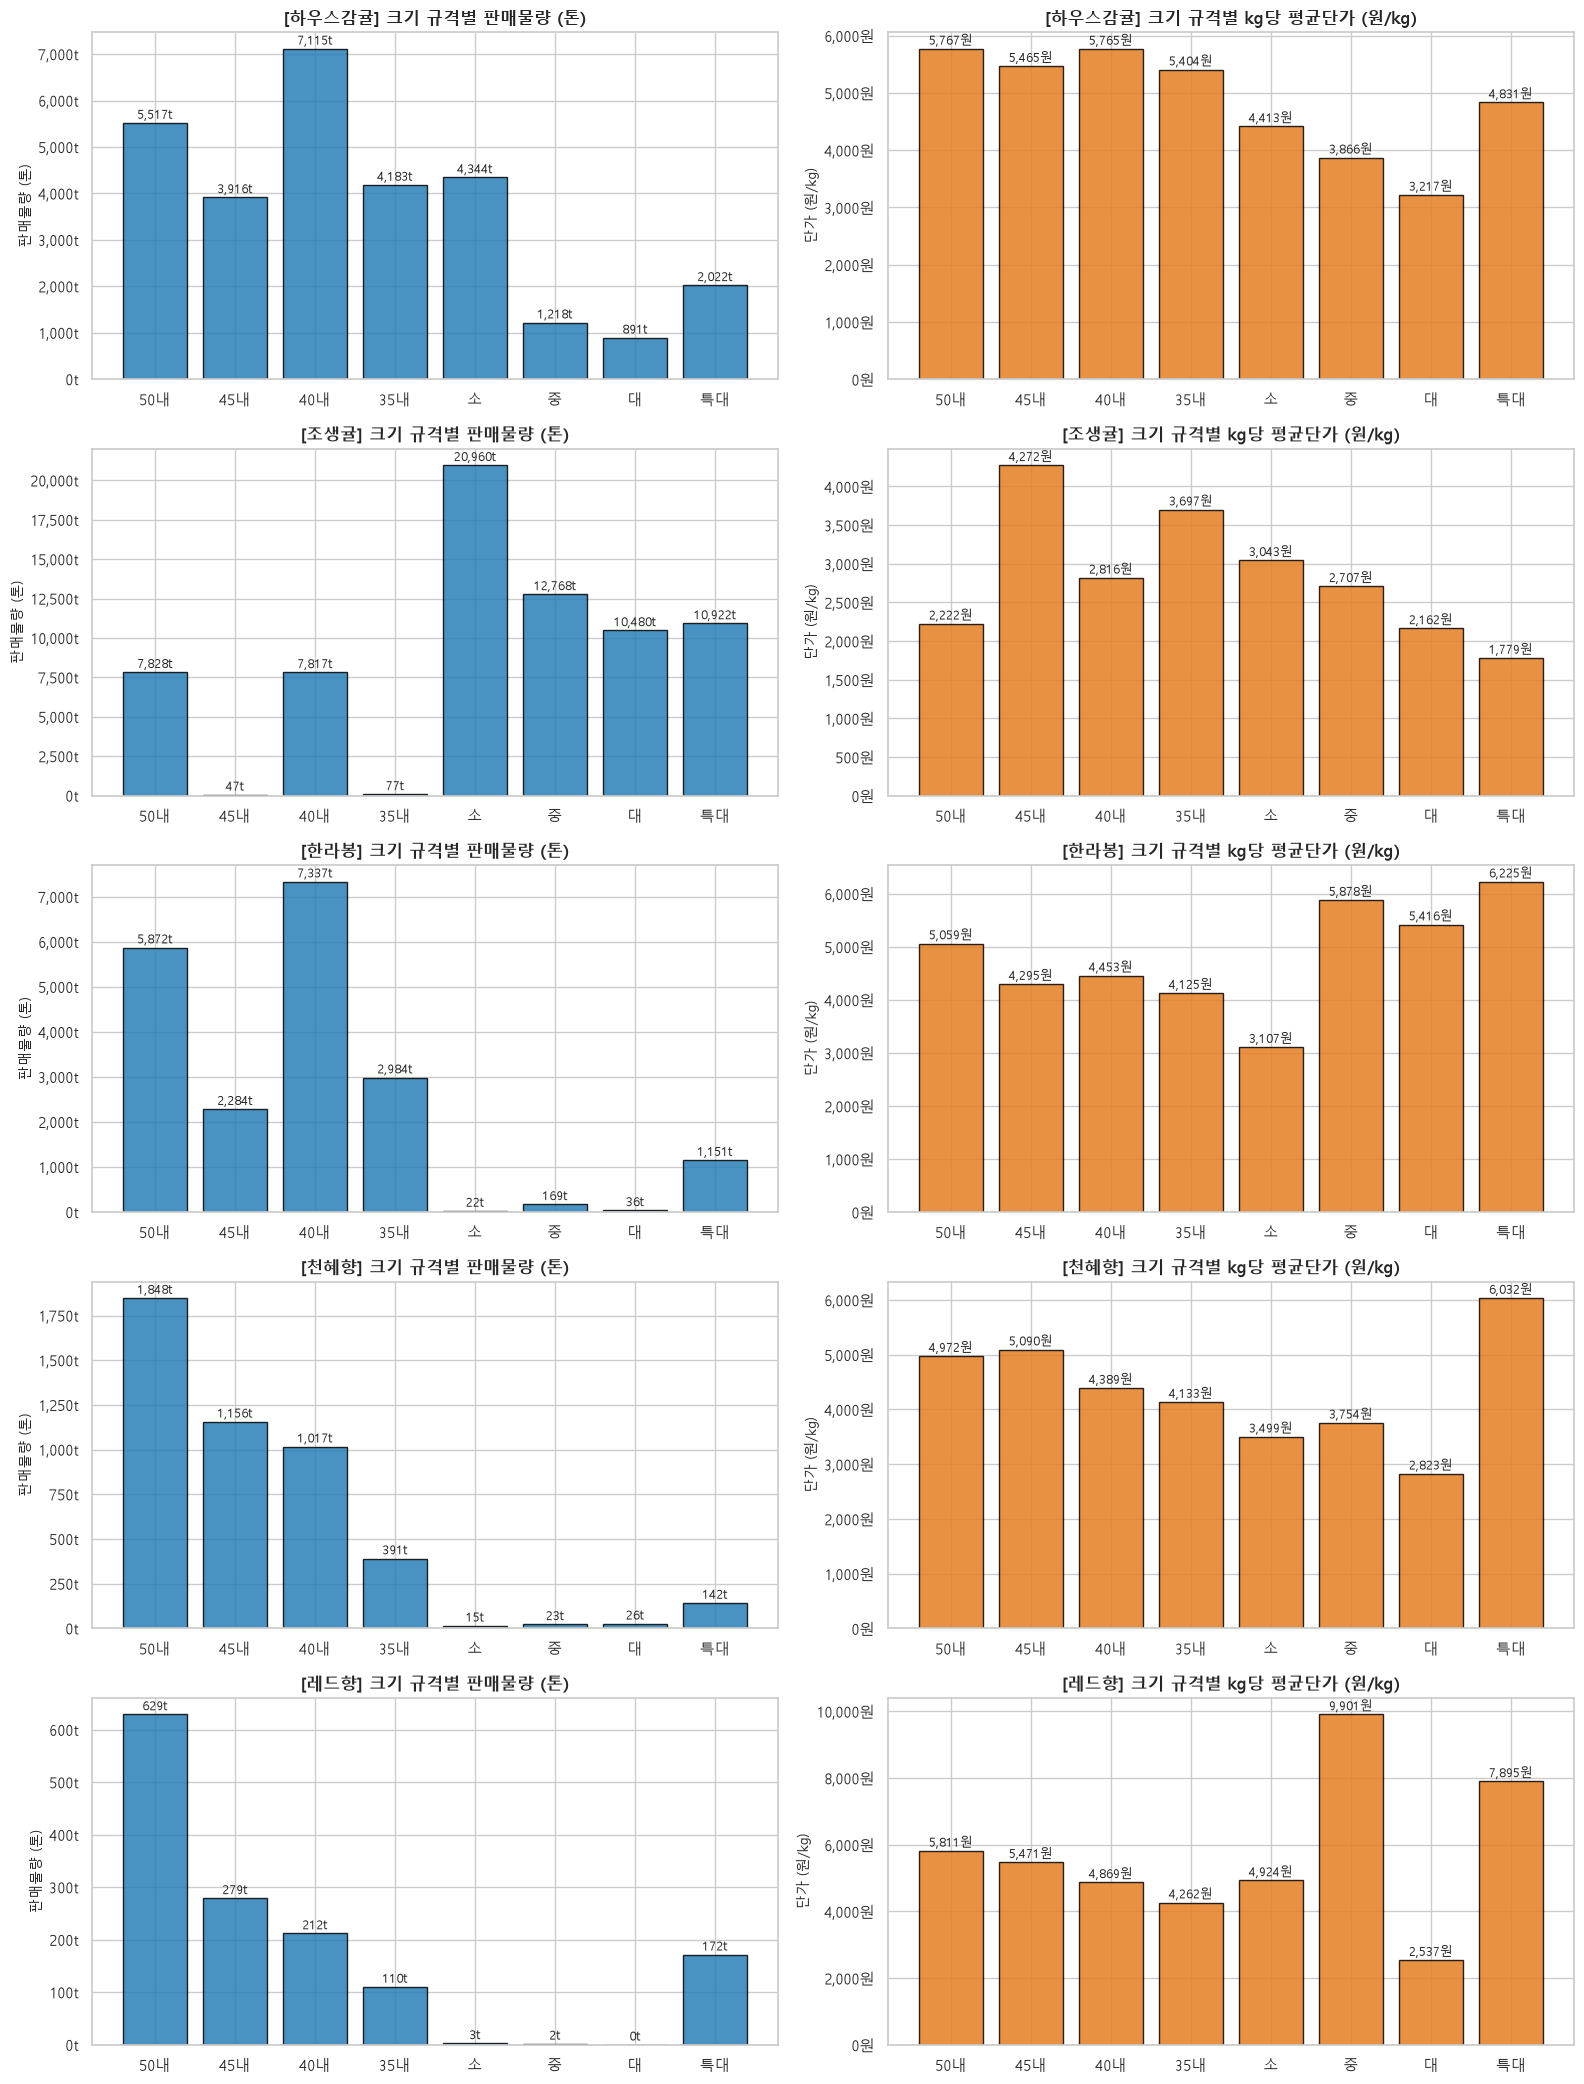

In [19]:
# 8-3) 【품종별 크기 분류 시각화】 주요 5대 품종별 크기 규격(지정 순서) 판매물량 및 판매단가 패널 차트
fig, axes = plt.subplots(len(target_varieties), 2, figsize=(16, 4.2 * len(target_varieties)))

for idx, var in enumerate(target_varieties):
    sub_data = variety_size_summary_df[variety_size_summary_df['품종'] == var]
    
    ax_vol = axes[idx, 0]
    bars_v = ax_vol.bar(sub_data['size'], sub_data['총판매물량_톤'], color='#2980b9', edgecolor='black', alpha=0.85)
    ax_vol.set_title(f"[{var}] 크기 규격별 판매물량 (톤)", fontsize=12, fontweight='bold')
    ax_vol.set_ylabel("판매물량 (톤)", fontsize=10)
    ax_vol.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
    for b in bars_v:
        h = b.get_height()
        ax_vol.annotate(f"{h:,.0f}t", (b.get_x() + b.get_width() / 2, h), textcoords="offset points", xytext=(0, 3), ha='center', fontsize=9)
        
    ax_prc = axes[idx, 1]
    bars_p = ax_prc.bar(sub_data['size'], sub_data['kg당평균단가_원'], color='#e67e22', edgecolor='black', alpha=0.85)
    ax_prc.set_title(f"[{var}] 크기 규격별 kg당 평균단가 (원/kg)", fontsize=12, fontweight='bold')
    ax_prc.set_ylabel("단가 (원/kg)", fontsize=10)
    ax_prc.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
    for b in bars_p:
        h = b.get_height()
        ax_prc.annotate(f"{h:,.0f}원", (b.get_x() + b.get_width() / 2, h), textcoords="offset points", xytext=(0, 3), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### 8-4) 【상자 크기별(3kg, 5kg, 10kg) × 과수 규격(50내/45내/40내/35내)】 품종별 평균가격 비교
> **분석 배경**: 상자의 포장 중량(3kg, 5kg, 10kg)에 따라 상자 내 과수(50내/45내/40내/35내)가 의미하는 **개별 과실 1개의 실제 중량과 크기**가 완전히 다릅니다.
> - **3kg 상자**: 35내(약 86g/개), 40내(약 75g/개), 45내(약 67g/개), 50내(약 60g/개) $
ightarrow$ 소과/소포장 중심 (주로 하우스감귤)
> - **5kg 상자**: 35내(약 143g/개), 40내(약 125g/개), 45내(약 111g/개), 50내(약 100g/개) $
ightarrow$ 중소과 중심 (조생귤, 하우스감귤)
> - **10kg 상자**: 35내(약 285g/개), 40내(약 250g/개), 45내(약 222g/개), 50내(약 200g/개) $
ightarrow$ 중대과/대과 중심 (천혜향, 레드향 등 만감류 대량 포장)
>
> 따라서 각 **품종별 × 상자크기별 × 과수규격별** kg당 평균단가(원/kg)와 상자당 평균가격(원/상자)을 비교 분석합니다.

In [20]:
# 8-4) 품종별 x 상자크기(3kg, 5kg, 10kg) x 과수규격(50내, 45내, 40내, 35내) 평균가격 집계
target_count_sizes = ['50내', '45내', '40내', '35내']
box_weights = [3.0, 5.0, 10.0]

sub_box = df[(df['size'].isin(target_count_sizes)) & (df['unit_weight'].isin(box_weights))].copy()
sub_box['box_weight'] = sub_box['unit_weight'].astype(int).astype(str) + 'kg'

major_citrus_vars = ['하우스감귤', '조생귤', '극조생감귤', '비가림감귤', '한라봉', '천혜향', '황금향', '레드향']
sub_box_major = sub_box[sub_box['variety'].isin(major_citrus_vars)].copy()

# 1) 품종 x 상자크기 x 과수규격 집계 테이블
box_size_agg = sub_box_major.groupby(['variety', 'box_weight', 'size']).agg(
    거래건수=('volume_kg', 'count'),
    총판매물량_톤=('volume_kg', lambda x: x.sum() / 1000.0),
    total_rev=('total_price', 'sum'),
    total_kg=('volume_kg', 'sum'),
    상자당평균가격=('box_price', 'mean')
).reset_index()

box_size_agg['kg당평균단가'] = (box_size_agg['total_rev'] / (box_size_agg['total_kg'] + 1e-8)).round(0)
box_size_agg['상자당평균가격'] = box_size_agg['상자당평균가격'].round(0)

# 2) 피벗 테이블: kg당 평균단가 (원/kg)
pivot_kg_price = box_size_agg.pivot_table(
    index=['variety', 'box_weight'],
    columns='size',
    values='kg당평균단가'
)[target_count_sizes]

# 3) 피벗 테이블: 상자당 평균가격 (원/상자)
pivot_box_price = box_size_agg.pivot_table(
    index=['variety', 'box_weight'],
    columns='size',
    values='상자당평균가격'
)[target_count_sizes]

print("=== 【1】 품종별 x 상자크기별 x 과수규격별 kg당 평균단가 (원/kg) ===")
display(pivot_kg_price.rename_axis(index={'variety': '품종', 'box_weight': '상자크기'}))

print("\n=== 【2】 품종별 x 상자크기별 x 과수규격별 상자당 평균가격 (원/상자) ===")
display(pivot_box_price.rename_axis(index={'variety': '품종', 'box_weight': '상자크기'}))

=== 【1】 품종별 x 상자크기별 x 과수규격별 kg당 평균단가 (원/kg) ===


size           50내      45내      40내     35내
품종    상자크기                                  
극조생감귤 10kg  1368.0      NaN   1643.0     NaN
      3kg   3558.0   3796.0   3912.0  3602.0
      5kg   1746.0   1371.0   2008.0  1111.0
레드향   10kg  5636.0   5115.0   4244.0  3295.0
      3kg   3667.0      NaN   5000.0  6585.0
      5kg   4201.0   4251.0   4711.0  4988.0
비가림감귤 10kg  1913.0      NaN   1399.0     NaN
      3kg   6531.0   4890.0   5769.0  5172.0
      5kg   3185.0   2790.0   3632.0  2877.0
조생귤   10kg  1194.0   3400.0   1501.0  3442.0
      3kg   4656.0   5297.0   4680.0  4006.0
      5kg   2259.0   2302.0   2858.0  2007.0
천혜향   10kg  4316.0   4608.0   4396.0  4108.0
      3kg   4019.0   4316.0   4578.0  4751.0
      5kg   2370.0   3070.0   2863.0  3251.0
하우스감귤 10kg  3117.0   1152.0   2178.0   925.0
      3kg   6292.0   6117.0   6186.0  6019.0
      5kg   4195.0   4094.0   3440.0  3018.0
한라봉   10kg  4443.0   4128.0   3978.0  3736.0
      3kg   6710.0  10098.0  15500.0  4743.0
      5kg   4413.0   3572.0   3492.0  3848.0
황금향   10kg  3564.0   3168.0   2627.0  1740.0
      3kg   5838.0   5478.0   5285.0  5161.0
      5kg   3994.0   3214.0   3740.0  2837.0


=== 【2】 품종별 x 상자크기별 x 과수규격별 상자당 평균가격 (원/상자) ===


size            50내      45내      40내      35내
품종    상자크기                                    
극조생감귤 10kg  12670.0      NaN  15352.0      NaN
      3kg   11225.0  11474.0  12704.0  11316.0
      5kg    8793.0   6917.0   9477.0   5847.0
레드향   10kg  49039.0  46237.0  40614.0  33512.0
      3kg   11000.0      NaN  15000.0  13000.0
      5kg   20901.0  20207.0  23508.0  23366.0
비가림감귤 10kg  14214.0      NaN  10417.0      NaN
      3kg   16112.0  14644.0  15737.0  14950.0
      5kg   15799.0  13619.0  18037.0  12250.0
조생귤   10kg  10890.0  34000.0  14186.0  34500.0
      3kg   13829.0  16164.0  15241.0  13415.0
      5kg   10990.0  14907.0  12453.0  12231.0
천혜향   10kg  41089.0  44075.0  41820.0  38224.0
      3kg   13877.0  10750.0  11512.0  10427.0
      5kg   11222.0  13162.0  13646.0  15560.0
하우스감귤 10kg  34790.0  14350.0  29324.0   8750.0
      3kg   18982.0  18941.0  19822.0  18878.0
      5kg   21382.0  21164.0  17907.0  15354.0
한라봉   10kg  36464.0  37134.0  38489.0  37447.0
      3kg   19014.0  29167.0  35943.0  16917.0
      5kg   18593.0  16194.0  16505.0  17675.0
황금향   10kg  37733.0  32653.0  31060.0  21286.0
      3kg   15558.0  14247.0  15127.0  14775.0
      5kg   16168.0  12321.0  15833.0  13772.0

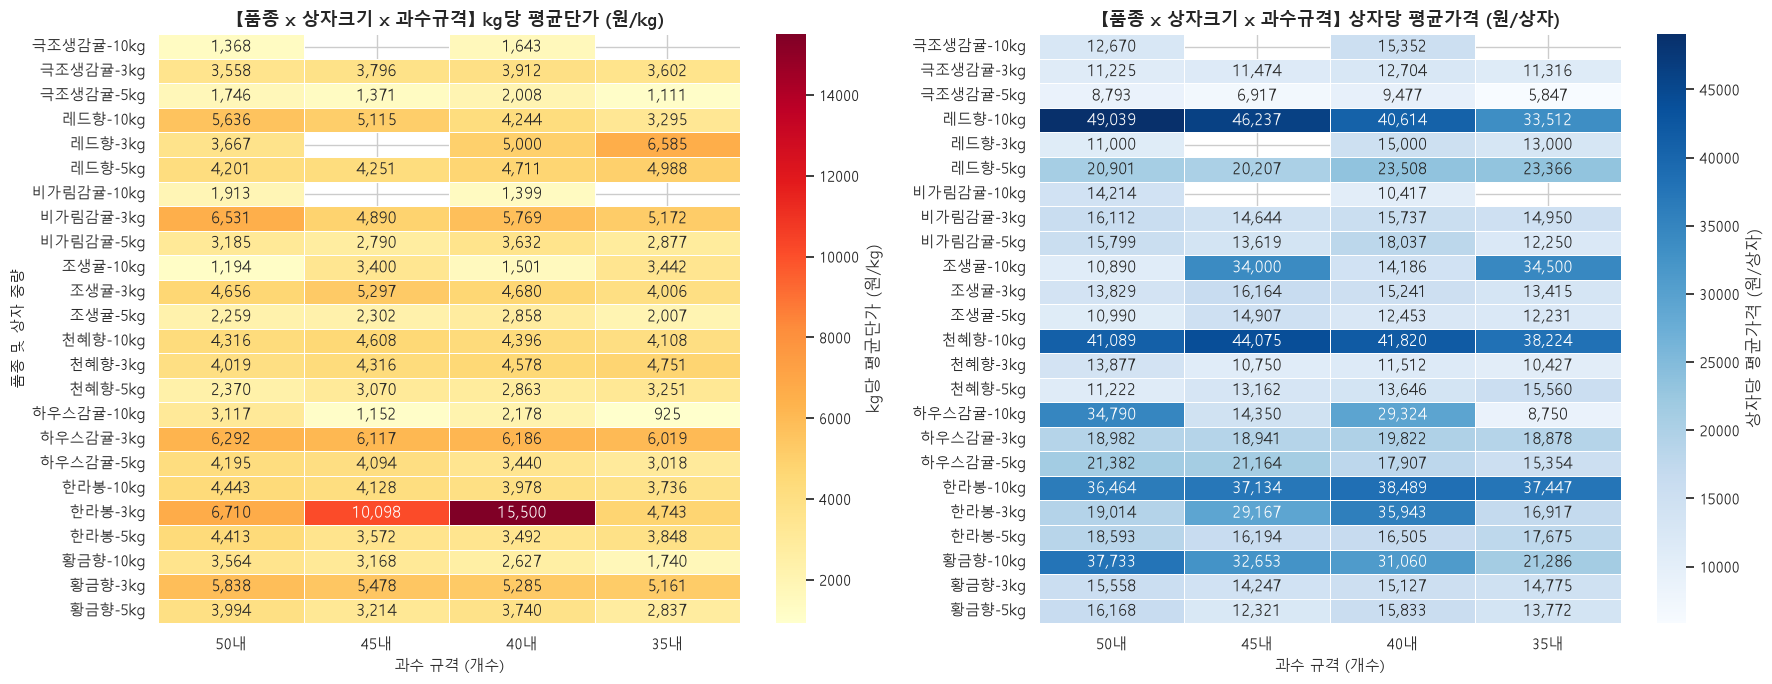

In [21]:
# 8-5) 상자크기별 과수규격 단가 비교 시각화 (히트맵 & 품종별 단가 비교)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# 히트맵: kg당 평균단가
sns.heatmap(pivot_kg_price, annot=True, fmt=',.0f', cmap='YlOrRd', ax=ax1, cbar_kws={'label': 'kg당 평균단가 (원/kg)'}, linewidths=0.5)
ax1.set_title("【품종 x 상자크기 x 과수규격】 kg당 평균단가 (원/kg)", fontsize=13, fontweight='bold')
ax1.set_xlabel("과수 규격 (개수)", fontsize=11)
ax1.set_ylabel("품종 및 상자 중량", fontsize=11)

# 히트맵: 상자당 평균가격
sns.heatmap(pivot_box_price, annot=True, fmt=',.0f', cmap='Blues', ax=ax2, cbar_kws={'label': '상자당 평균가격 (원/상자)'}, linewidths=0.5)
ax2.set_title("【품종 x 상자크기 x 과수규격】 상자당 평균가격 (원/상자)", fontsize=13, fontweight='bold')
ax2.set_xlabel("과수 규격 (개수)", fontsize=11)
ax2.set_ylabel("", fontsize=11)

plt.tight_layout()
plt.show()

## 9. [크기별 × 품종별] 항목별 날짜에 따른 거래량 및 가격 시계열 추이 분석
- **분석 개요**: 8번에서 지정 순서(`50내 -> 45내 -> 40내 -> 35내 -> 소 -> 중 -> 대 -> 특대`)로 분류된 주요 크기 항목들에 대해, **날짜별(월별 시계열) 거래물량과 가격의 변화 추이를 시각화**합니다.
- **분석 항목**:
  1. **[월별 거래물량 추이]**: 품종별(하우스감귤, 조생귤, 한라봉 등) 지정 크기 항목의 월별 거래물량(톤) 시계열 변화
  2. **[월별 판매가격 추이]**: 품종별 지정 크기 항목의 월별 kg당 평균단가(원/kg) 시계열 변화 (크기별 프리미엄 및 계절 가격 변동)
  3. **[핵심 품종별 거래물량 & 가격 2축(Dual-Axis) 시계열]**: 대표 품종(하우스감귤, 조생귤) 내 핵심 크기 항목의 날짜별 수급-가격 상관 추이
  4. **[복합 교차 히트맵]**: 품종 × 등급, 품종 × 크기별(지정 순서 적용) 평균단가 히트맵

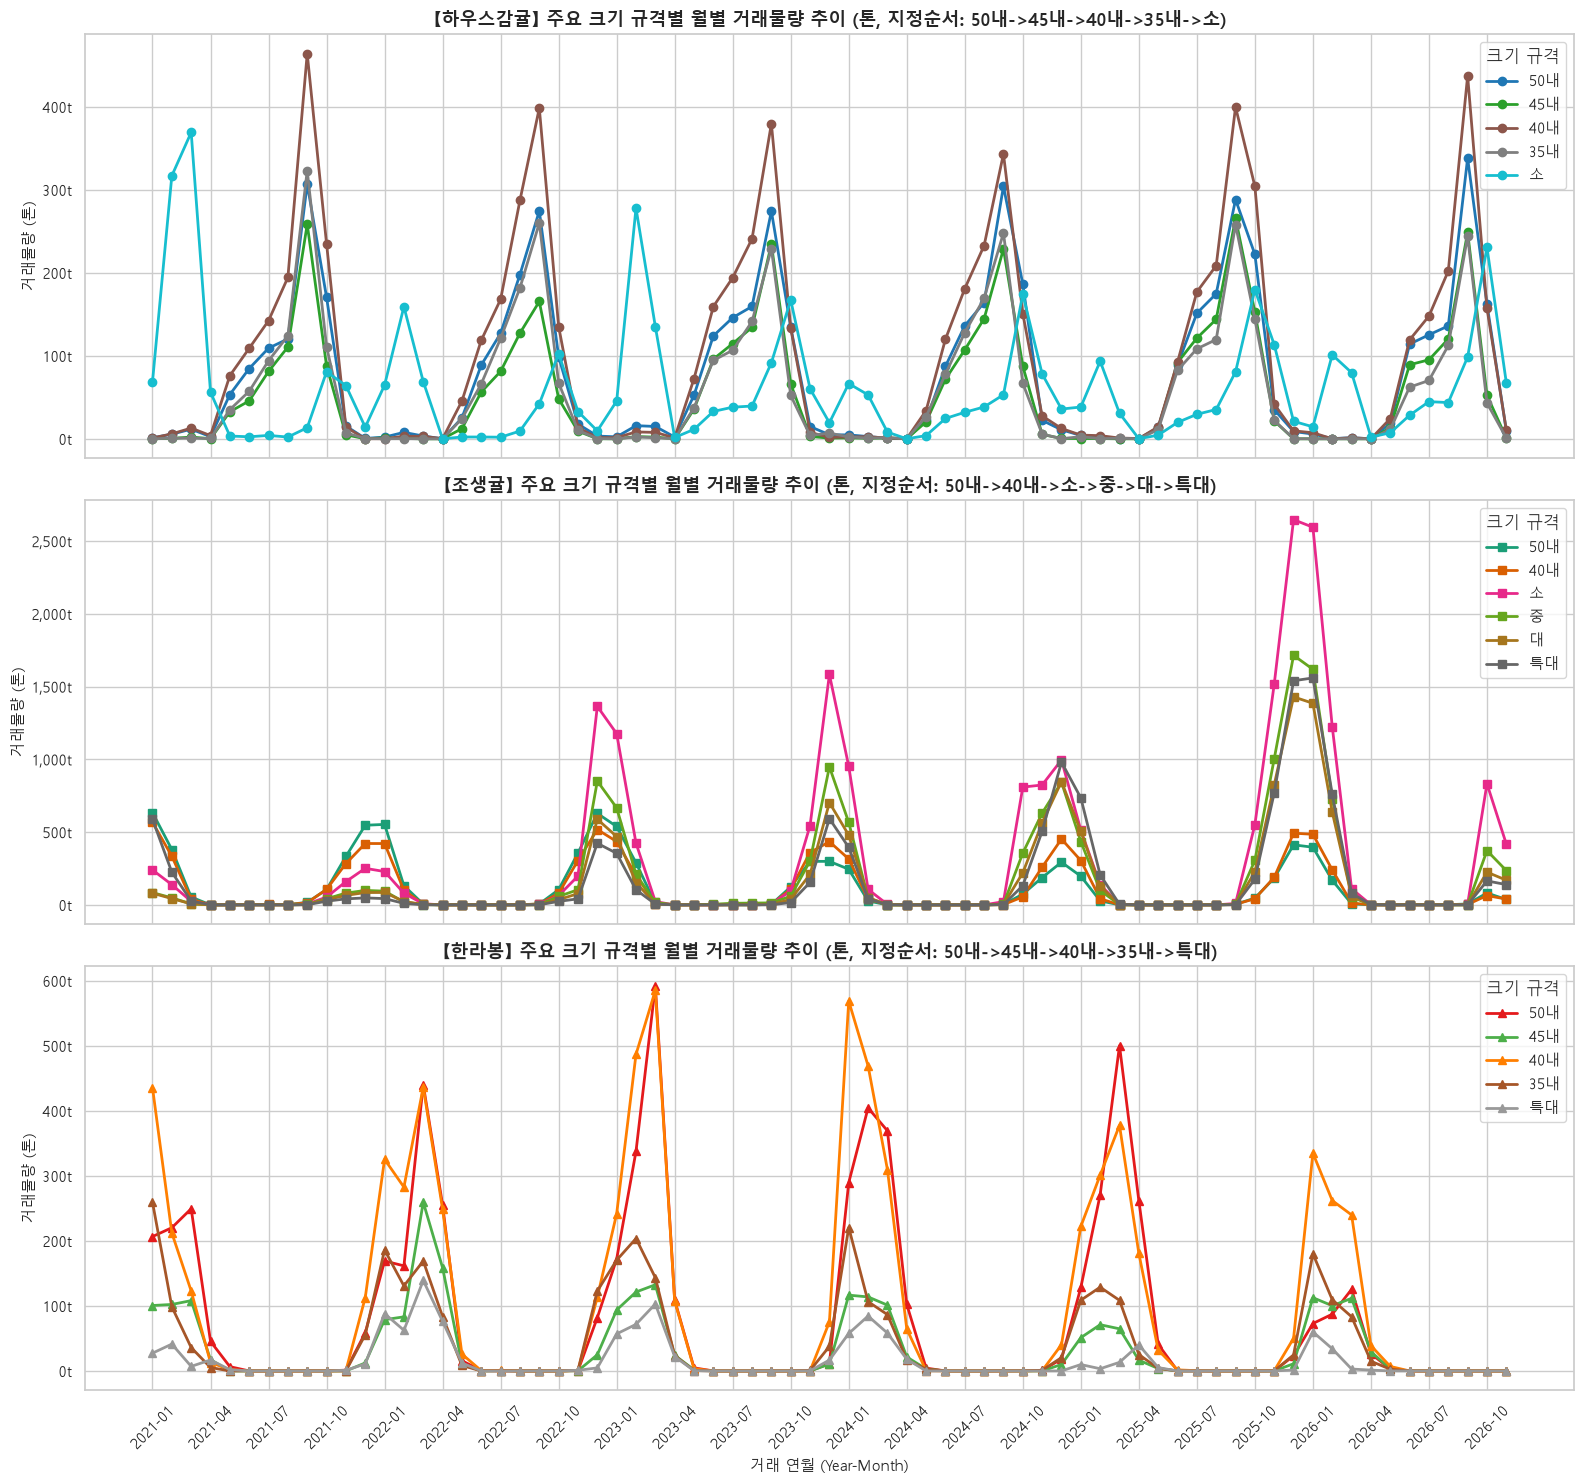

In [22]:
# 9-1) 【품종별 크기 항목】 월별 거래물량(톤) 시계열 추이 그래프 (전체 기간 71개월 시계열 동기화)
fig, axes = plt.subplots(3, 1, figsize=(16, 15), sharex=True)

all_months = sorted(df['year_month'].unique())
size_order = ['50내', '45내', '40내', '35내', '소', '중', '대', '특대']

# 1) 하우스감귤: 지정 순서 중 상위 규격 (전체 71개월 reindex)
house_sizes = [s for s in size_order if s in ['50내', '45내', '40내', '35내', '소']]
house_ts = df[(df['variety'] == '하우스감귤') & (df['size'].isin(house_sizes))].groupby(['year_month', 'size'])['volume_kg'].sum().unstack(fill_value=0) / 1000.0
house_ts = house_ts.reindex(index=all_months, fill_value=0.0).reindex(columns=house_sizes)

house_ts.plot(ax=axes[0], marker='o', linewidth=2, colormap='tab10')
axes[0].set_title("【하우스감귤】 주요 크기 규격별 월별 거래물량 추이 (톤, 지정순서: 50내->45내->40내->35내->소)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("거래물량 (톤)", fontsize=11)
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
axes[0].legend(title='크기 규격', loc='upper right')

# 2) 조생귤: 지정 순서 중 상위 규격 (전체 71개월 reindex)
joseng_sizes = [s for s in size_order if s in ['50내', '40내', '소', '중', '대', '특대']]
joseng_ts = df[(df['variety'] == '조생귤') & (df['size'].isin(joseng_sizes))].groupby(['year_month', 'size'])['volume_kg'].sum().unstack(fill_value=0) / 1000.0
joseng_ts = joseng_ts.reindex(index=all_months, fill_value=0.0).reindex(columns=joseng_sizes)

joseng_ts.plot(ax=axes[1], marker='s', linewidth=2, colormap='Dark2')
axes[1].set_title("【조생귤】 주요 크기 규격별 월별 거래물량 추이 (톤, 지정순서: 50내->40내->소->중->대->특대)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("거래물량 (톤)", fontsize=11)
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
axes[1].legend(title='크기 규격', loc='upper right')

# 3) 한라봉(코드 07): 지정 순서 중 상위 규격 (전체 71개월 reindex)
halla_sizes = [s for s in size_order if s in ['50내', '45내', '40내', '35내', '특대']]
halla_ts = df[(df['variety'] == '한라봉') & (df['size'].isin(halla_sizes))].groupby(['year_month', 'size'])['volume_kg'].sum().unstack(fill_value=0) / 1000.0
halla_ts = halla_ts.reindex(index=all_months, fill_value=0.0).reindex(columns=halla_sizes)

halla_ts.plot(ax=axes[2], marker='^', linewidth=2, colormap='Set1')
axes[2].set_title("【한라봉】 주요 크기 규격별 월별 거래물량 추이 (톤, 지정순서: 50내->45내->40내->35내->특대)", fontsize=13, fontweight='bold')
axes[2].set_ylabel("거래물량 (톤)", fontsize=11)
axes[2].set_xlabel("거래 연월 (Year-Month)", fontsize=11)
axes[2].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
axes[2].legend(title='크기 규격', loc='upper right')

tick_idx = list(range(0, len(all_months), 3))
axes[2].set_xticks(tick_idx)
axes[2].set_xticklabels([all_months[i] for i in tick_idx], rotation=45)

plt.tight_layout()
plt.show()

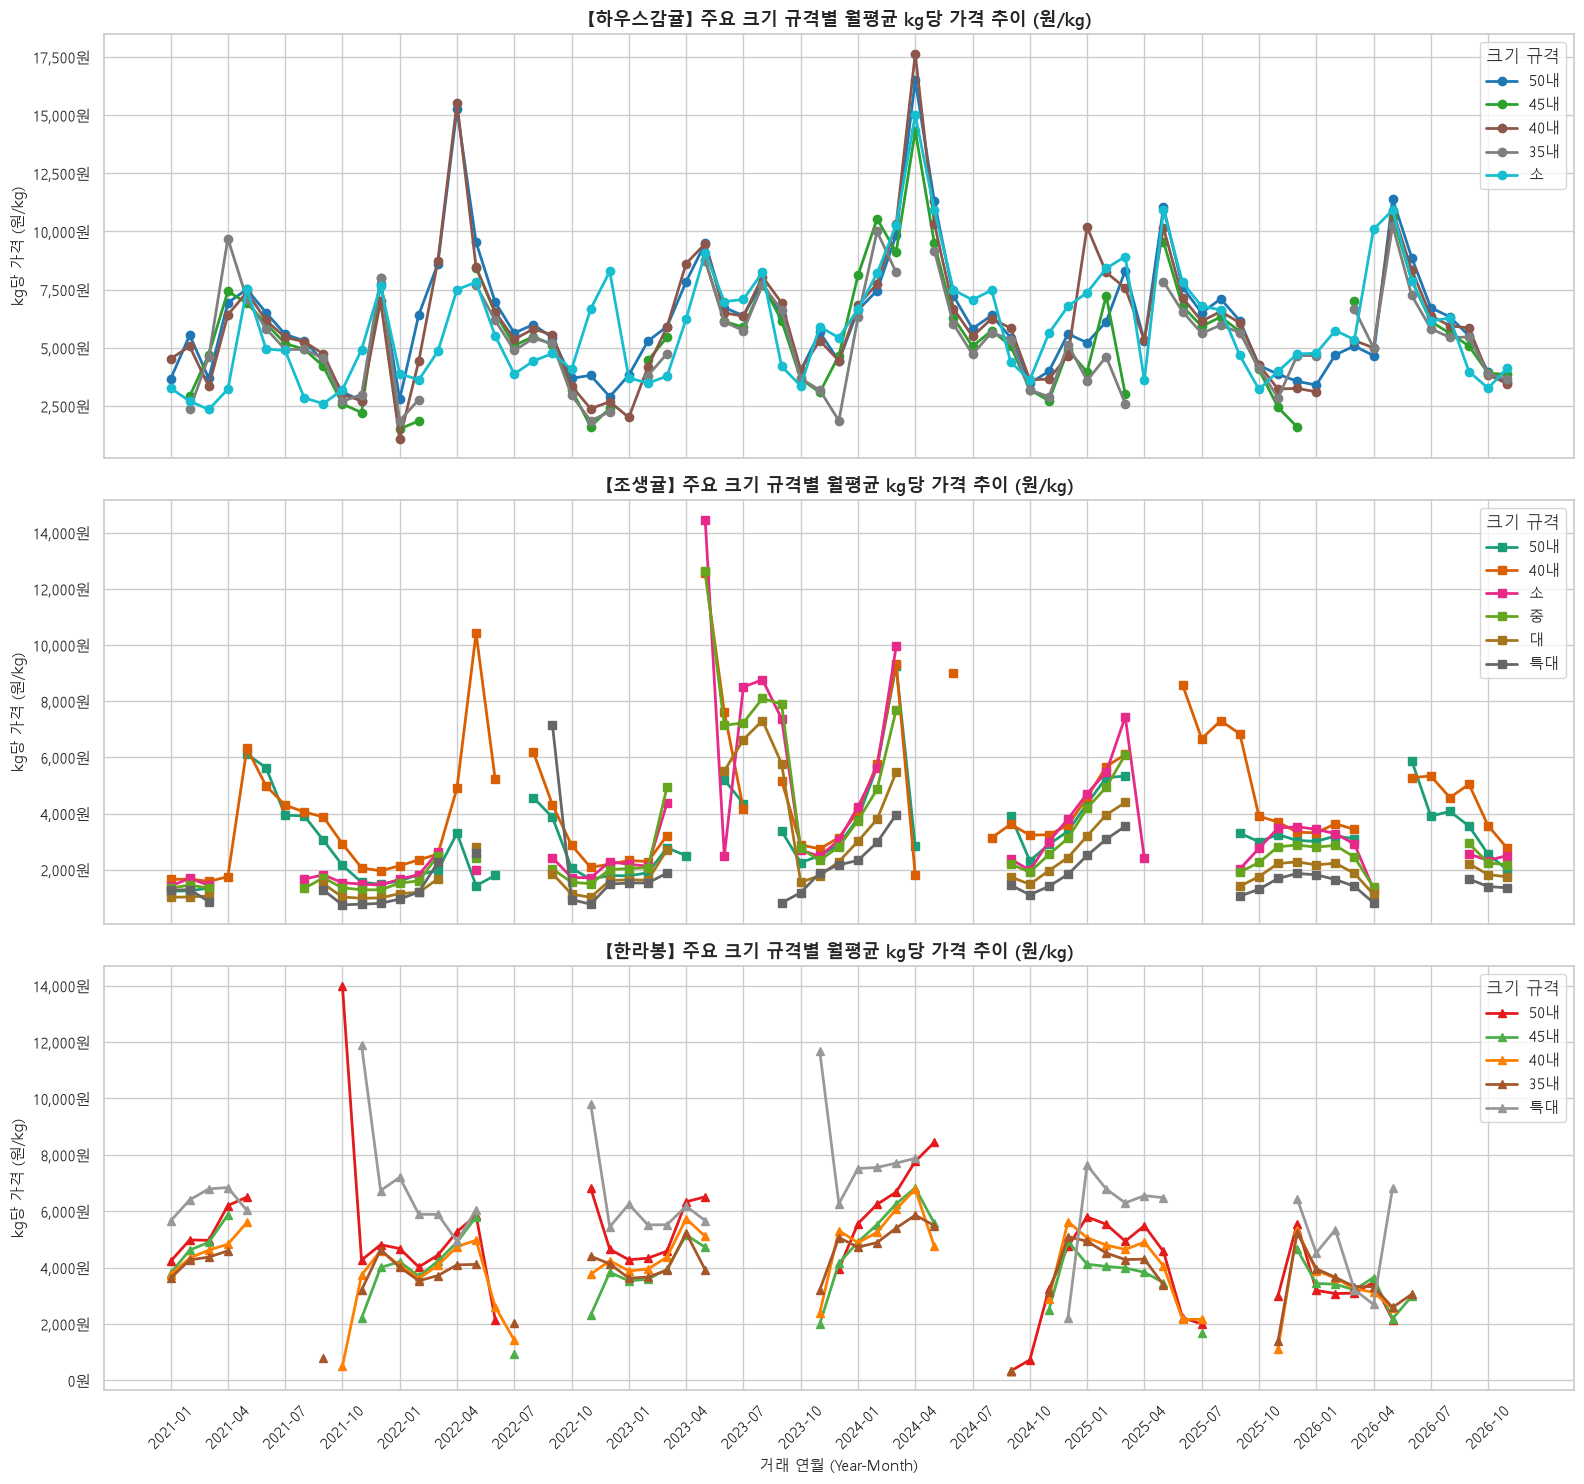

In [23]:
# 9-2) 【품종별 크기 항목】 월별 kg당 평균 판매가격(원/kg) 시계열 추이 그래프 (전체 기간 71개월 시계열 동기화)
fig, axes = plt.subplots(3, 1, figsize=(16, 15), sharex=True)

def calc_unit_price_ts(variety_name, sizes):
    sub = df[(df['variety'] == variety_name) & (df['size'].isin(sizes))]
    grouped = sub.groupby(['year_month', 'size']).agg(vol=('volume_kg', 'sum'), price=('total_price', 'sum')).reset_index()
    grouped['unit_price'] = grouped['price'] / (grouped['vol'] + 1e-8)
    p = grouped.pivot(index='year_month', columns='size', values='unit_price')
    p = p.reindex(index=all_months)  # 71개월 전체 시계열 축 동기화
    return p.reindex(columns=[s for s in sizes if s in p.columns])

house_prc_ts = calc_unit_price_ts('하우스감귤', house_sizes)
house_prc_ts.plot(ax=axes[0], marker='o', linewidth=2, colormap='tab10')
axes[0].set_title("【하우스감귤】 주요 크기 규격별 월평균 kg당 가격 추이 (원/kg)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("kg당 가격 (원/kg)", fontsize=11)
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
axes[0].legend(title='크기 규격', loc='upper right')

joseng_prc_ts = calc_unit_price_ts('조생귤', joseng_sizes)
joseng_prc_ts.plot(ax=axes[1], marker='s', linewidth=2, colormap='Dark2')
axes[1].set_title("【조생귤】 주요 크기 규격별 월평균 kg당 가격 추이 (원/kg)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("kg당 가격 (원/kg)", fontsize=11)
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
axes[1].legend(title='크기 규격', loc='upper right')

halla_prc_ts = calc_unit_price_ts('한라봉', halla_sizes)
halla_prc_ts.plot(ax=axes[2], marker='^', linewidth=2, colormap='Set1')
axes[2].set_title("【한라봉】 주요 크기 규격별 월평균 kg당 가격 추이 (원/kg)", fontsize=13, fontweight='bold')
axes[2].set_ylabel("kg당 가격 (원/kg)", fontsize=11)
axes[2].set_xlabel("거래 연월 (Year-Month)", fontsize=11)
axes[2].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
axes[2].legend(title='크기 규격', loc='upper right')

tick_idx = list(range(0, len(all_months), 3))
axes[2].set_xticks(tick_idx)
axes[2].set_xticklabels([all_months[i] for i in tick_idx], rotation=45)

plt.tight_layout()
plt.show()

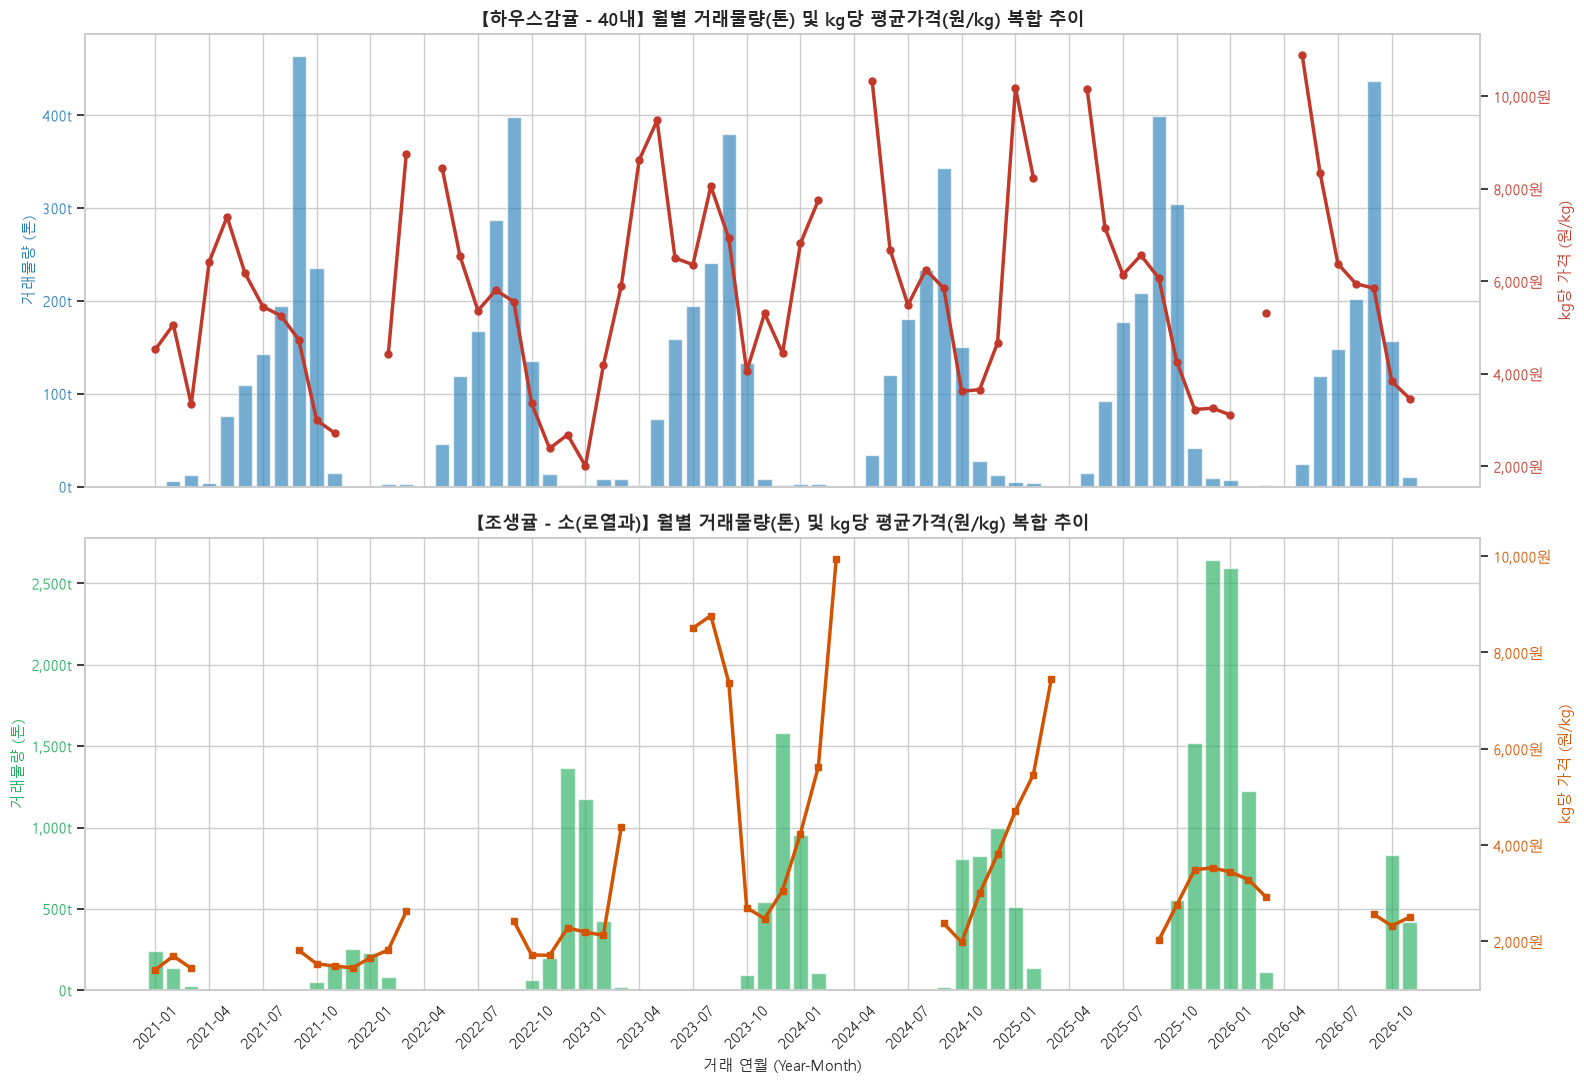

In [24]:
# 9-3) 【대표 품종 x 크기 규격】 날짜별 거래물량 & 판매가격 복합(Dual-Axis) 시계열 추이 (71개월 시계열 동기화 & 비출하기 노이즈 정제)
fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(16, 11), sharex=True)

all_months = sorted(df['year_month'].unique())
x_indices = np.arange(len(all_months))

# (1) [하우스감귤 - 40내 규격] 월별 거래물량 및 가격 추이 (전체 71개월 reindex)
sub_h40 = df[(df['variety'] == '하우스감귤') & (df['size'] == '40내')].groupby('year_month').agg(
    vol_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    total_rev=('total_price', 'sum'),
    total_kg=('volume_kg', 'sum')
).reindex(all_months).fillna({'vol_ton': 0.0, 'total_rev': 0.0, 'total_kg': 0.0})
sub_h40['unit_price'] = np.where(sub_h40['vol_ton'] >= 1.0, sub_h40['total_rev'] / (sub_h40['total_kg'] + 1e-8), np.nan)

color_vol1 = '#2980b9'
color_prc1 = '#c0392b'

ax1.bar(x_indices, sub_h40['vol_ton'], color=color_vol1, alpha=0.65, label='거래물량 (톤)')
ax1.set_ylabel('거래물량 (톤)', color=color_vol1, fontsize=11)
ax1.tick_params(axis='y', labelcolor=color_vol1)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
ax1.set_title("【하우스감귤 - 40내】 월별 거래물량(톤) 및 kg당 평균가격(원/kg) 복합 추이", fontsize=13, fontweight='bold')

ax2 = ax1.twinx()
ax2.plot(x_indices, sub_h40['unit_price'], color=color_prc1, marker='o', linewidth=2.5, markersize=5, label='kg당 가격 (원/kg)')
ax2.set_ylabel('kg당 가격 (원/kg)', color=color_prc1, fontsize=11)
ax2.tick_params(axis='y', labelcolor=color_prc1)
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax2.grid(False)

# (2) [조생귤 - 소 규격] 월별 거래물량 및 가격 추이 (전체 71개월 reindex & 비출하기 극소수 이상치 정제)
sub_j_so = df[(df['variety'] == '조생귤') & (df['size'] == '소')].groupby('year_month').agg(
    vol_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    total_rev=('total_price', 'sum'),
    total_kg=('volume_kg', 'sum')
).reindex(all_months).fillna({'vol_ton': 0.0, 'total_rev': 0.0, 'total_kg': 0.0})
sub_j_so['unit_price'] = np.where(sub_j_so['vol_ton'] >= 1.0, sub_j_so['total_rev'] / (sub_j_so['total_kg'] + 1e-8), np.nan)

color_vol2 = '#27ae60'
color_prc2 = '#d35400'

ax3.bar(x_indices, sub_j_so['vol_ton'], color=color_vol2, alpha=0.65, label='거래물량 (톤)')
ax3.set_ylabel('거래물량 (톤)', color=color_vol2, fontsize=11)
ax3.tick_params(axis='y', labelcolor=color_vol2)
ax3.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
ax3.set_title("【조생귤 - 소(로열과)】 월별 거래물량(톤) 및 kg당 평균가격(원/kg) 복합 추이", fontsize=13, fontweight='bold')
ax3.set_xlabel("거래 연월 (Year-Month)", fontsize=11)

ax4 = ax3.twinx()
ax4.plot(x_indices, sub_j_so['unit_price'], color=color_prc2, marker='s', linewidth=2.5, markersize=5, label='kg당 가격 (원/kg)')
ax4.set_ylabel('kg당 가격 (원/kg)', color=color_prc2, fontsize=11)
ax4.tick_params(axis='y', labelcolor=color_prc2)
ax4.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax4.grid(False)

tick_idx = list(range(0, len(all_months), 3))
ax3.set_xticks(tick_idx)
ax3.set_xticklabels([all_months[i] for i in tick_idx], rotation=45)

plt.tight_layout()
plt.show()

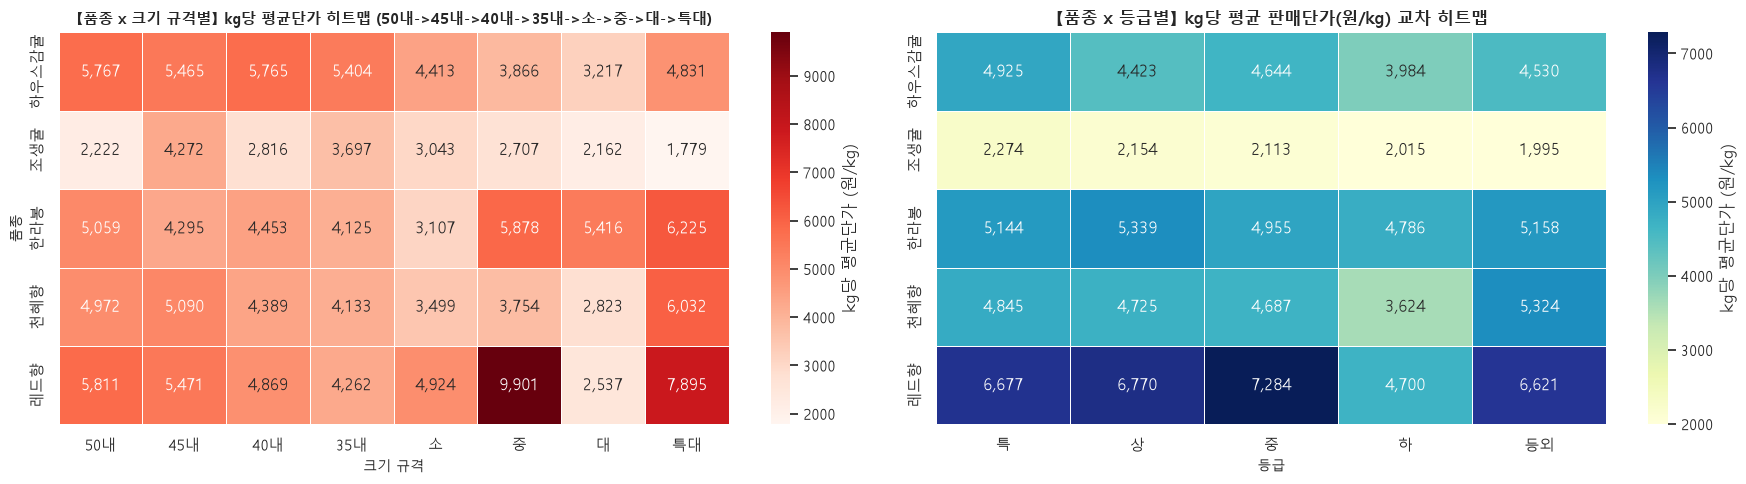

In [25]:
# 9-4) [품종 x 크기], [품종 x 등급] 교차 평균단가 히트맵 (크기 지정 순서 적용)
top_5_vars = ['하우스감귤', '조생귤', '한라봉', '천혜향', '레드향']
main_sizes_for_cross = ['50내', '45내', '40내', '35내', '소', '중', '대', '특대']

fig, (ax_h1, ax_h2) = plt.subplots(1, 2, figsize=(18, 5))

cross_sz_df = df[df['variety'].isin(top_5_vars) & df['size'].isin(main_sizes_for_cross)].copy()
pivot_sz = cross_sz_df.pivot_table(index='variety', columns='size', values=['total_price', 'volume_kg'], aggfunc='sum')
pivot_sz_unit = (pivot_sz['total_price'] / (pivot_sz['volume_kg'] + 1e-8)).reindex(index=top_5_vars, columns=main_sizes_for_cross)

sns.heatmap(pivot_sz_unit, annot=True, fmt=',.0f', cmap='Reds', ax=ax_h1, cbar_kws={'label': 'kg당 평균단가 (원/kg)'}, linewidths=0.5)
ax_h1.set_title("【품종 x 크기 규격별】 kg당 평균단가 히트맵 (50내->45내->40내->35내->소->중->대->특대)", fontsize=11, fontweight='bold')
ax_h1.set_xlabel("크기 규격", fontsize=10)
ax_h1.set_ylabel("품종", fontsize=10)

main_5_grades = ['특', '상', '중', '하', '등외']
cross_gr_df = df[df['variety'].isin(top_5_vars) & df['grade'].isin(main_5_grades)].copy()
pivot_gr = cross_gr_df.pivot_table(index='variety', columns='grade', values=['total_price', 'volume_kg'], aggfunc='sum')
pivot_gr_unit = (pivot_gr['total_price'] / (pivot_gr['volume_kg'] + 1e-8)).reindex(index=top_5_vars, columns=main_5_grades)

sns.heatmap(pivot_gr_unit, annot=True, fmt=',.0f', cmap='YlGnBu', ax=ax_h2, cbar_kws={'label': 'kg당 평균단가 (원/kg)'}, linewidths=0.5)
ax_h2.set_title("【품종 x 등급별】 kg당 평균 판매단가(원/kg) 교차 히트맵", fontsize=12, fontweight='bold')
ax_h2.set_xlabel("등급", fontsize=10)
ax_h2.set_ylabel("", fontsize=10)

plt.tight_layout()
plt.show()

## 10. 전처리 완료 데이터 내보내기 (Export)
- 정제 및 파생변수(`trd_type`, `is_auction` 등) 생성이 완료된 데이터프레임을 저장합니다.
  1. `data/preprocessed_citrus_data.csv`: 전체 정제 거래 데이터
  2. `data/preprocessed_citrus_data_auction_only.csv`: **수의계약이 제외된 순수 경매 전용 데이터**
- 다음 단계인 머신러닝/딥러닝 모델링(예: TFT, 시계열 예측)에 바로 활용할 수 있습니다.

In [26]:
# 전처리 완료 데이터 저장
output_clean_path = data_dir / "preprocessed_citrus_data.csv"
output_auction_path = data_dir / "preprocessed_citrus_data_auction_only.csv"

export_cols = [
    'date', 'year', 'month', 'year_month', 'weekday',
    'whsl_mrkt_cd', 'whsl_mrkt_nm',
    'trd_se', 'trd_type', 'is_auction', 'is_negotiated',
    'gds_sclsf_cd', 'variety',
    'grd_cd', 'grade',
    'sz_cd', 'size',
    'pkg_nm', 'unit_weight', 'box_weight', 'box_unit',
    'volume_kg', 'box_qty',
    'box_price', 'total_price', 'unit_price_kg'
]

export_cols = [c for c in export_cols if c in df.columns]

print(f"1) 전체 전처리 데이터 저장 시작: {output_clean_path.resolve()}")
t0 = time.time()
df[export_cols].to_csv(output_clean_path, index=False, encoding='utf-8-sig')
print(f"전체 CSV 저장 완료! 소요시간: {time.time() - t0:.2f}초 ({len(df):,}건, {output_clean_path.stat().st_size / (1024*1024):.2f} MB)")

# 2) 수의계약 제외(경매 전용) 데이터 저장
print(f"\n2) 수의계약 제외(경매 전용) 데이터 저장 시작: {output_auction_path.resolve()}")
t0 = time.time()
df_auction_export = df[df['trd_type'] != '수의계약'][export_cols]
df_auction_export.to_csv(output_auction_path, index=False, encoding='utf-8-sig')
print(f"경매 전용 CSV 저장 완료! 소요시간: {time.time() - t0:.2f}초 ({len(df_auction_export):,}건, {output_auction_path.stat().st_size / (1024*1024):.2f} MB)")


1) 전체 전처리 데이터 저장 시작: D:\hongdonjoo\ai\project\ugasungsi\data\preprocessed_citrus_data.csv
전체 CSV 저장 완료! 소요시간: 17.18초 (1,722,631건, 273.77 MB)

2) 수의계약 제외(경매 전용) 데이터 저장 시작: D:\hongdonjoo\ai\project\ugasungsi\data\preprocessed_citrus_data_auction_only.csv
경매 전용 CSV 저장 완료! 소요시간: 18.56초 (1,479,916건, 232.36 MB)


## 11. [신규] 감귤 가격 및 거래량 예측함수를 위한 다차원 전처리 및 비수기 분리 시스템

사용자가 원하는 조건별(등급, 품종, 크기, 상자규격)로 거래량과 가격을 정밀하게 예측할 수 있도록 다차원 시계열 피처 및 비수기 분리 전처리를 수행합니다.

### 【선택 항목 체계】
1. **등급 (5대 기준)**: `특`, `상`, `중`, `하`, `전체`
2. **품종 (10대 대표 품종)**: `조생귤`, `한라봉`, `극조생감귤`, `하우스감귤`, `비가림감귤`, `천혜향`, `레드향`, `타이벡감귤`, `황금향`, `진지향`
3. **크기 (품종별 상위 5대 규격 + 전체)**: 품종별 거래건수가 가장 많은 상위 5개 크기(과수규격) 및 `전체`
4. **상자 (품종별 상위 3대 규격 + 전체)**: 품종별 거래건수가 가장 많은 상위 3개 상자 포장단위(예: 3kg상자, 5kg상자, 10kg상자 등) 및 `전체`
5. **비수기 분리 로직**: 품종별 **5일 이동평균 거래량(5-day Rolling Volume)**을 기준으로 연중 최고 출하시기 대비 **5%~10% 이하로 출하되는 기간을 비수기(off-season)**로 자동 분리 및 라벨링하여 이상치/노이즈 왜곡을 방지합니다.


In [39]:
# 11-1) 10대 품종별 메타데이터(등급, 상위 5대 크기, 상위 3대 상자 규격) 구축 및 요약
import json

# 10대 품종 및 동의어 매핑
TARGET_VARIETY_MAP = {
    '조생귤': '조생귤',
    '한라봉': '한라봉',
    '극조생감귤': '극조생감귤',
    '하우스감귤': '하우스감귤', '하우스': '하우스감귤',
    '비가림감귤': '비가림감귤', '비가림': '비가림감귤',
    '천혜향': '천혜향',
    '레드향': '레드향',
    '타이벡감귤': '타이벡감귤', '타이백': '타이벡감귤',
    '황금향': '황금향', '항금향': '황금향',
    '진지향': '진지향'
}

TARGET_VARIETIES = [
    '조생귤', '한라봉', '극조생감귤', '하우스감귤', '비가림감귤',
    '천혜향', '레드향', '타이벡감귤', '황금향', '진지향'
]

TARGET_GRADES = ['특', '상', '중', '하', '전체']

# 2021년 이후 기준 시계열 필터링 및 일별 날짜축 생성
df_auction = df[df['trd_type'] != '수의계약'].copy()
df_auction_2021 = df_auction[df_auction['date'] >= '2021-01-01'].copy()
all_daily_dates = pd.date_range('2021-01-01', df_auction_2021['date'].max(), freq='D')

# 품종별 메타데이터 추출
citrus_metadata = {}
summary_rows = []

for v in TARGET_VARIETIES:
    v_df = df_auction_2021[df_auction_2021['variety'] == v]
    
    # 거래건수 상위 5대 유효 크기
    valid_sizes = v_df[~v_df['size'].isin(['미지정', '.', '', '기타'])]['size'].value_counts()
    top_5_sizes = valid_sizes.head(5).index.tolist()
    
    # 거래건수 상위 3대 상자 규격단위
    top_3_boxes = v_df['box_unit'].value_counts().head(3).index.tolist()
    
    # 일별 거래량 및 5일 이동평균 기준치 산출
    daily_v = v_df.groupby('date')['volume_kg'].sum().reindex(all_daily_dates, fill_value=0.0)
    roll5 = daily_v.rolling(5, min_periods=1).mean()
    peak_5d_ma = float(roll5.max())
    off_5pct = peak_5d_ma * 0.05
    off_10pct = peak_5d_ma * 0.10
    
    citrus_metadata[v] = {
        'variety_name': v,
        'total_records': int(len(v_df)),
        'total_volume_ton': round(float(v_df['volume_kg'].sum() / 1000.0), 1),
        'avg_price_won_kg': round(float(v_df['total_price'].sum() / (v_df['volume_kg'].sum() + 1e-8)), 1),
        'grades': TARGET_GRADES,
        'top_5_sizes': top_5_sizes + ['전체'],
        'top_3_boxes': top_3_boxes + ['전체'],
        'peak_5d_ma_ton': round(peak_5d_ma / 1000.0, 2),
        'off_season_5pct_ton': round(off_5pct / 1000.0, 2),
        'off_season_10pct_ton': round(off_10pct / 1000.0, 2)
    }
    
    summary_rows.append({
        '품종명': v,
        '총 거래건수': f"{len(v_df):,}건",
        '총 거래량(톤)': f"{v_df['volume_kg'].sum()/1000:,.1f}톤",
        'kg당 평균단가': f"{v_df['total_price'].sum() / (v_df['volume_kg'].sum() + 1e-8):,.0f}원",
        '상위 5대 크기': ", ".join(top_5_sizes),
        '상위 3대 상자': ", ".join(top_3_boxes),
        '5일이평 피크(톤)': f"{peak_5d_ma/1000:,.1f}톤",
        '비수기 기준(5~10%)': f"{off_5pct/1000:.1f}~{off_10pct/1000:.1f}톤 이하"
    })

summary_df = pd.DataFrame(summary_rows)
print("=== [감귤 10대 품종 다차원 예측 선택항목 메타데이터 요약] ===")
display(summary_df)


=== [감귤 10대 품종 다차원 예측 선택항목 메타데이터 요약] ===


품종명,총 거래건수,총 거래량(톤),kg당 평균단가,상위 5대 크기,상위 3대 상자,5일이평 피크(톤),비수기 기준(5~10%)
조생귤,"268,299건","451,202.5톤","2,224원","50내, 소, 40내, 19개, 대","5kg상자, 10kg상자, 5kg파렛트","1,540.9톤",77.0~154.1톤 이하
한라봉,"290,391건","95,296.7톤","5,074원","10개, 9개, 12개, 11개, 40내","3kg상자, 9kg상자, 5kg상자",559.9톤,28.0~56.0톤 이하
극조생감귤,"81,372건","91,081.8톤","1,709원","50내, 40내, 소, 19개, 22개","5kg상자, 10kg상자, 5kg파렛트",638.2톤,31.9~63.8톤 이하
하우스감귤,"273,234건","78,327.9톤","4,701원","40내, 35내, 45내, 50내, 30내","3kg상자, 5kg상자, 0.5kg상자",308.2톤,15.4~30.8톤 이하
비가림감귤,"55,636건","33,363.5톤","3,300원","특대, 50내, 소, 대, 중","5kg상자, 5kg파렛트, 3kg상자",195.7톤,9.8~19.6톤 이하
천혜향,"93,886건","30,440.7톤","4,676원","10개, 12개, 11개, 13개, 9개","3kg상자, 9kg상자, 5kg상자",372.0톤,18.6~37.2톤 이하
레드향,"77,560건","23,788.8톤","6,642원","12개, 10개, 13개, 11개, 14개","3kg상자, 5kg상자, 9kg상자",340.6톤,17.0~34.1톤 이하
타이벡감귤,"14,804건","13,779.4톤","3,096원","소, 대, 중, 50내, 특대","5kg상자, 5kg파렛트, 5kg기타",124.9톤,6.2~12.5톤 이하
황금향,"16,339건","3,628.5톤","3,961원","10개, 13개, 12개, 11개, 30내","3kg상자, 5kg상자, 9kg상자",30.0톤,1.5~3.0톤 이하
진지향,"14,918건","2,609.3톤","4,731원","40내, 50내, 35내, 30내, 12개","3kg상자, 5kg상자, 9kg상자",16.2톤,0.8~1.6톤 이하


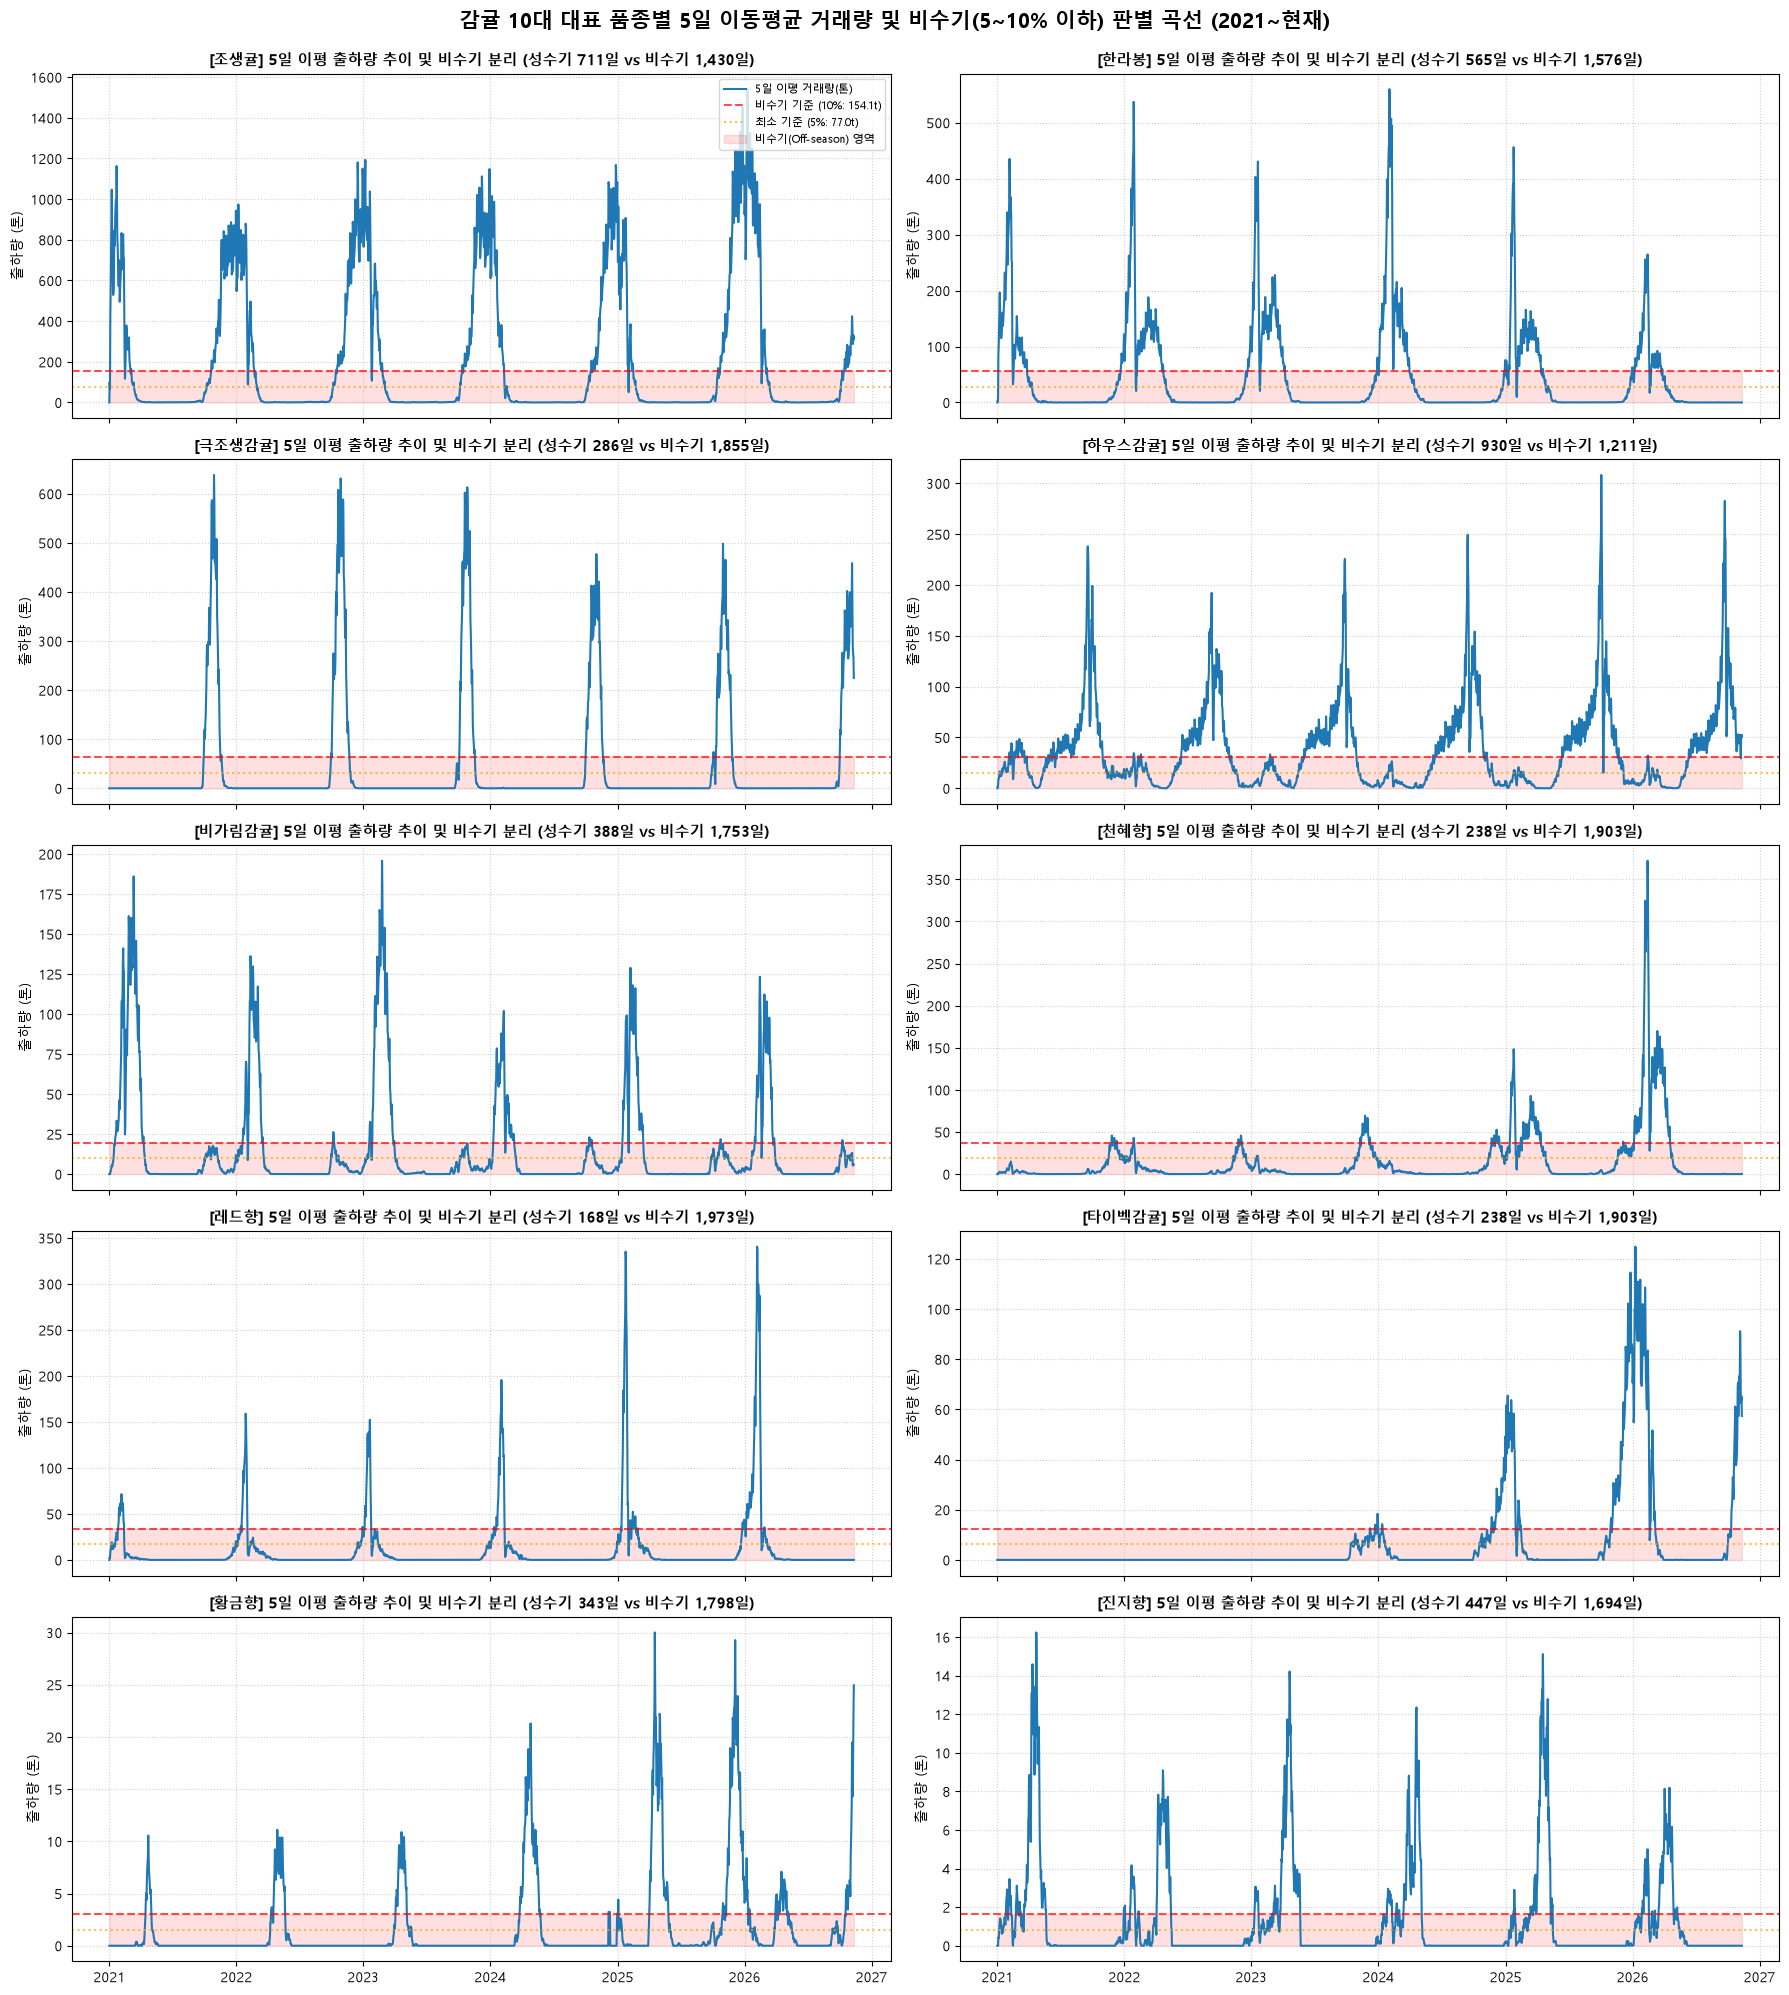

품종명,최대 출하월,"성수기(출하월, >10%)","비수기(휴면월, <=10%)",연간 성수기 일수,연간 비수기 일수
조생귤,12월,"[1, 2, 10, 11, 12]월","[3, 4, 5, 6, 7, 8, 9]월",711일 (33.2%),"1,430일 (66.8%)"
한라봉,1월,"[1, 2, 3, 4, 12]월","[5, 6, 7, 8, 9, 10, 11]월",565일 (26.4%),"1,576일 (73.6%)"
극조생감귤,10월,"[10, 11]월","[1, 2, 3, 4, 5, 6, 7, 8, 9, 12]월",286일 (13.4%),"1,855일 (86.6%)"
하우스감귤,9월,"[2, 6, 7, 8, 9, 10, 11]월","[1, 3, 4, 5, 12]월",930일 (43.4%),"1,211일 (56.6%)"
비가림감귤,2월,"[1, 2, 3, 10]월","[4, 5, 6, 7, 8, 9, 11, 12]월",388일 (18.1%),"1,753일 (81.9%)"
천혜향,2월,"[1, 2, 3, 4, 11, 12]월","[5, 6, 7, 8, 9, 10]월",238일 (11.1%),"1,903일 (88.9%)"
레드향,1월,"[1, 2, 12]월","[3, 4, 5, 6, 7, 8, 9, 10, 11]월",168일 (7.8%),"1,973일 (92.2%)"
타이벡감귤,12월,"[1, 2, 10, 11, 12]월","[3, 4, 5, 6, 7, 8, 9]월",238일 (11.1%),"1,903일 (88.9%)"
황금향,4월,"[4, 5, 11, 12]월","[1, 2, 3, 6, 7, 8, 9, 10]월",343일 (16.0%),"1,798일 (84.0%)"
진지향,4월,"[1, 2, 3, 4, 5]월","[6, 7, 8, 9, 10, 11, 12]월",447일 (20.9%),"1,694일 (79.1%)"


=== [10대 품종별 출하시기 및 비수기 판정 요약표] ===


In [40]:
# 11-2) 품종별 5일 이동평균 거래량 산출 및 비수기(5~10% 이하) 자동 판별 시각화
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
fig, axes = plt.subplots(5, 2, figsize=(18, 20), sharex=True)
axes = axes.flatten()

season_summary = []

for i, v in enumerate(TARGET_VARIETIES):
    ax = axes[i]
    v_df = df_auction_2021[df_auction_2021['variety'] == v]
    daily_v = v_df.groupby('date')['volume_kg'].sum().reindex(all_daily_dates, fill_value=0.0)
    roll5 = daily_v.rolling(5, min_periods=1).mean() / 1000.0  # 톤 단위
    
    peak_val = roll5.max()
    thresh_5 = peak_val * 0.05
    thresh_10 = peak_val * 0.10
    
    is_off = roll5 <= thresh_10
    active_days = (~is_off).sum()
    off_days = is_off.sum()
    
    # 5일 이동평균 선
    ax.plot(all_daily_dates, roll5, color='#1f77b4', lw=1.5, label='5일 이평 거래량(톤)')
    
    # 비수기 영역 음영 표시 (10% 이하 구간)
    ax.axhline(thresh_10, color='red', linestyle='--', alpha=0.7, label=f'비수기 기준 (10%: {thresh_10:.1f}t)')
    ax.axhline(thresh_5, color='orange', linestyle=':', alpha=0.7, label=f'최소 기준 (5%: {thresh_5:.1f}t)')
    ax.fill_between(all_daily_dates, 0, thresh_10, color='red', alpha=0.12, label='비수기(Off-season) 영역')
    
    ax.set_title(f'[{v}] 5일 이평 출하량 추이 및 비수기 분리 (성수기 {active_days:,}일 vs 비수기 {off_days:,}일)', fontsize=11, fontweight='bold')
    ax.set_ylabel('출하량 (톤)')
    ax.grid(True, linestyle=':', alpha=0.6)
    if i == 0:
        ax.legend(loc='upper right', fontsize=8)
        
    # 월별 성수기/비수기 판정
    monthly_v = daily_v.groupby(daily_v.index.month).mean()
    peak_month = monthly_v.idxmax()
    active_months = monthly_v[monthly_v > monthly_v.max() * 0.10].index.tolist()
    off_months = [m for m in range(1, 13) if m not in active_months]
    
    season_summary.append({
        '품종명': v,
        '최대 출하월': f"{peak_month}월",
        '성수기(출하월, >10%)': f"{active_months}월",
        '비수기(휴면월, <=10%)': f"{off_months}월",
        '연간 성수기 일수': f"{active_days:,}일 ({(active_days/len(all_daily_dates))*100:.1f}%)",
        '연간 비수기 일수': f"{off_days:,}일 ({(off_days/len(all_daily_dates))*100:.1f}%)"
    })

plt.suptitle('감귤 10대 대표 품종별 5일 이동평균 거래량 및 비수기(5~10% 이하) 판별 곡선 (2021~현재)', fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

print("=== [10대 품종별 출하시기 및 비수기 판정 요약표] ===")
display(pd.DataFrame(season_summary))


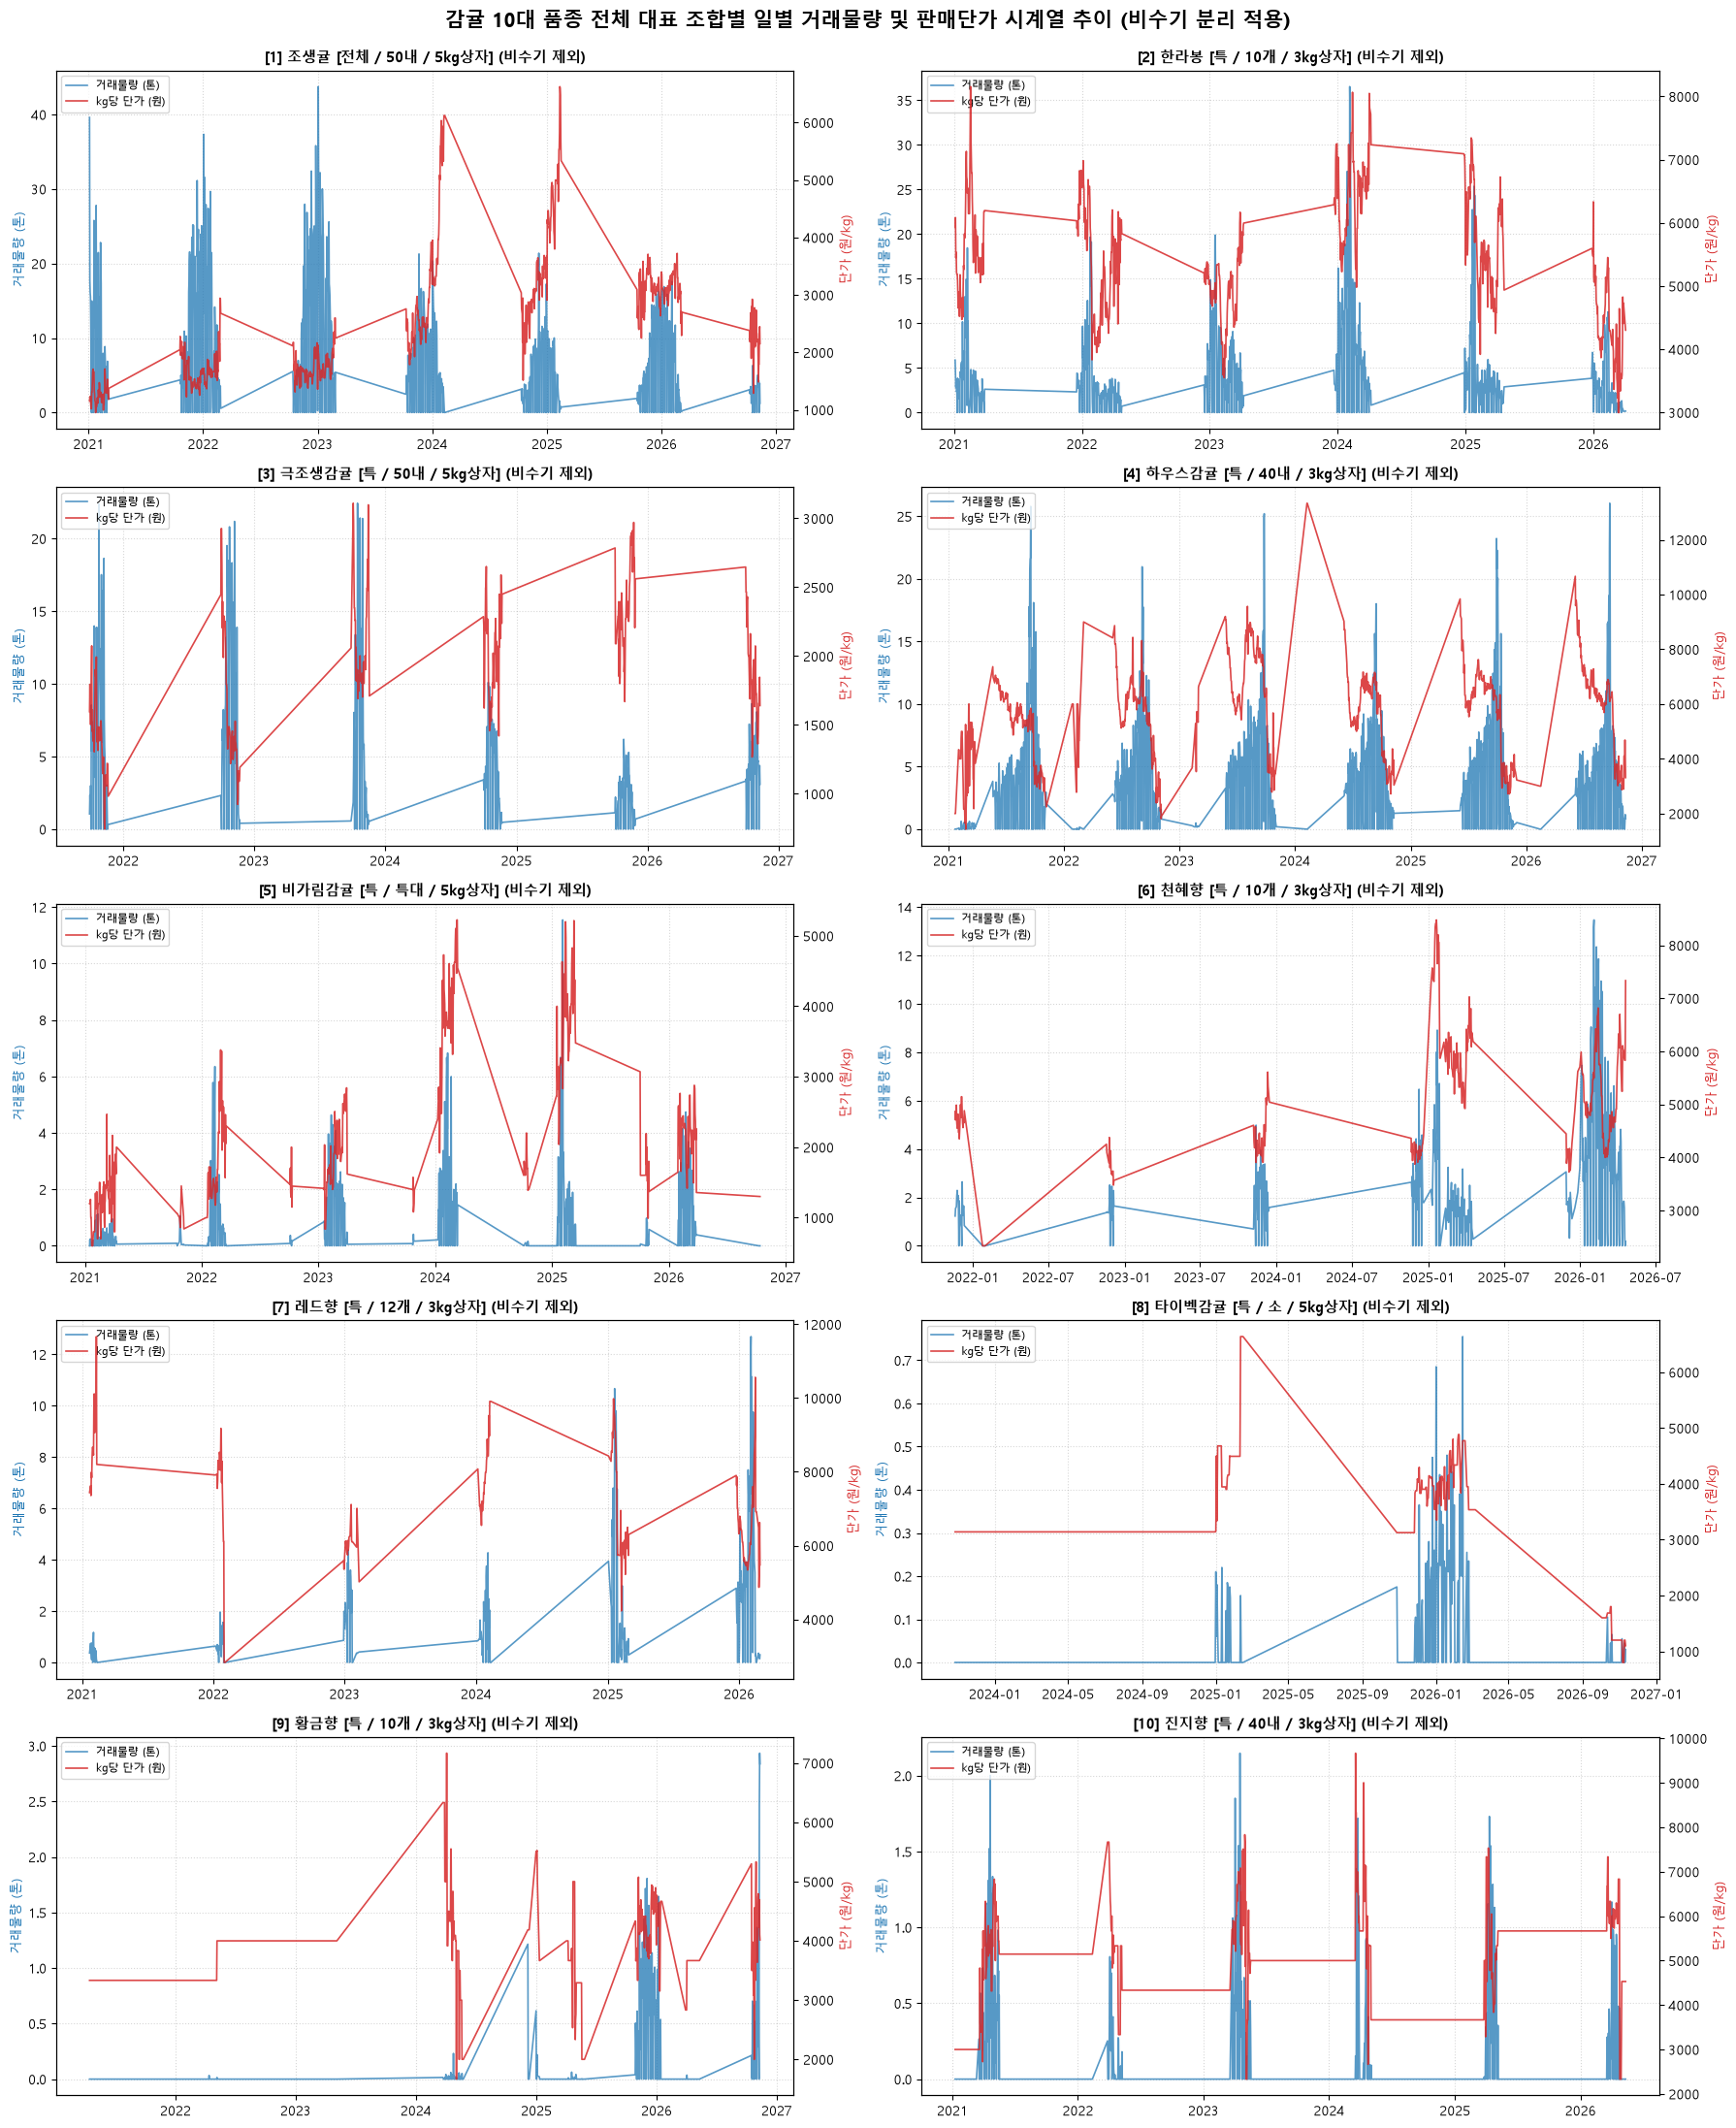

번호,품종명,등급,크기,상자규격,비수기 제외,유효 데이터 일수,총 물량(톤),평균 거래단가
1,조생귤,전체,50내,5kg상자,적용,749일,"6,553.7톤","2,247원/kg"
2,한라봉,특,10개,3kg상자,적용,620일,"2,770.2톤","5,723원/kg"
3,극조생감귤,특,50내,5kg상자,적용,301일,"1,648.3톤","1,723원/kg"
4,하우스감귤,특,40내,3kg상자,적용,"1,039일","4,696.8톤","6,081원/kg"
5,비가림감귤,특,특대,5kg상자,적용,454일,487.4톤,"2,583원/kg"
6,천혜향,특,10개,3kg상자,적용,314일,834.5톤,"5,303원/kg"
7,레드향,특,12개,3kg상자,적용,210일,459.9톤,"7,165원/kg"
8,타이벡감귤,특,소,5kg상자,적용,275일,15.9톤,"4,041원/kg"
9,황금향,특,10개,3kg상자,적용,369일,66.8톤,"4,250원/kg"
10,진지향,특,40내,3kg상자,적용,517일,103.9톤,"5,686원/kg"


=== [10대 품종 전체 대표 예측 시계열 추출 요약표] ===


In [41]:
# 11-3) 선택항목별(품종, 등급, 크기, 상자, 비수기 제외) 예측용 일별 시계열 데이터 추출 함수 및 10대 품종 전체 시연
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

def get_citrus_timeseries_for_prediction(
    df_source,
    variety='조생귤',
    grade='전체',
    size='전체',
    box='전체',
    off_season_pct=0.08,  # 5% ~ 10% (0.05 ~ 0.10)
    exclude_off_season=False,
    exclude_non_trading_days=True, # 일요일 및 경매 0건 공휴일 제외
    min_date='2021-01-01'
):
    """
    사용자 선택항목(품종, 등급, 크기, 상자)에 부합하는 일별 시계열 데이터셋을 생성하고,
    품종별 5일 이동평균 기반 비수기 라벨링 및 필터링을 수행합니다.
    
    Parameters:
    -----------
    df_source : DataFrame (경매 데이터프레임)
    variety : str (10대 품종명 또는 동의어)
    grade : str ('특', '상', '중', '하', '전체')
    size : str (품종별 상위 5대 규격 또는 '전체')
    box : str (품종별 상위 3대 상자규격 예: '5kg상자' 또는 '전체')
    off_season_pct : float (비수기 임계 비율, 0.05~0.10, 기본값 0.08)
    exclude_off_season : bool (True인 경우 비수기 일자 완전 제외)
    min_date : str (시작 기준일, 기본 '2021-01-01')
    
    Returns:
    --------
    daily_ts : DataFrame (일별 date, volume_kg, unit_price_kg, box_qty, is_off_season 등 포함)
    """
    v_std = TARGET_VARIETY_MAP.get(variety, variety)
    if v_std not in TARGET_VARIETIES:
        raise ValueError(f"지원되지 않는 품종입니다: '{variety}'. 지원 목록: {TARGET_VARIETIES}")
    
    # 1. 기준 필터링 (품종 및 시작일)
    sub = df_source[(df_source['variety'] == v_std) & (df_source['date'] >= min_date)].copy()
    
    # 2. 등급(Grade) 조건
    if grade != '전체':
        sub = sub[sub['grade'] == grade]
        
    # 3. 크기(Size) 조건
    if size != '전체':
        sub = sub[sub['size'] == size]
        
    # 4. 상자(Box) 조건 (box_unit 또는 box_weight)
    if box != '전체':
        sub = sub[(sub['box_unit'] == box) | (sub['box_weight'] == box)]
        
    # 5. 일별 시계열 인덱스 구축 (일요일 및 경매 0건 공휴일 제외)
    max_d = df_source['date'].max()
    if exclude_non_trading_days:
        market_daily = df_source[df_source['date'] >= min_date].groupby('date')['volume_kg'].count()
        valid_trading_days = market_daily[(market_daily.index.dayofweek != 6) & (market_daily > 0)].index
        date_range = valid_trading_days
    else:
        date_range = pd.date_range(min_date, max_d, freq='D')
    
    daily_ts = sub.groupby('date', as_index=False).agg(
        volume_kg=('volume_kg', 'sum'),
        total_price=('total_price', 'sum'),
        box_qty=('box_qty', 'sum'),
        deal_count=('volume_kg', 'count'),
        market_count=('whsl_mrkt_cd', 'nunique') if 'whsl_mrkt_cd' in sub.columns else ('date', 'count')
    ).sort_values('date').set_index('date').reindex(date_range, fill_value=0.0).reset_index()
    daily_ts.rename(columns={'index': 'date'}, inplace=True)
    
    # 가중평균 kg당 단가 및 상자당 단가 계산
    daily_ts['unit_price_kg'] = np.where(
        daily_ts['volume_kg'] > 0,
        (daily_ts['total_price'] / daily_ts['volume_kg']).round(1),
        np.nan
    )
    daily_ts['avg_box_price'] = np.where(
        daily_ts['box_qty'] > 0,
        (daily_ts['total_price'] / daily_ts['box_qty']).round(1),
        np.nan
    )
    
    # 결측 단가는 직전 유효 거래단가로 전진 보간 (ffill -> bfill)
    daily_ts['unit_price_kg_filled'] = daily_ts['unit_price_kg'].ffill().bfill().fillna(0.0)
    
    # 6. 품종 전체 기준 5일 이동평균 및 비수기 자동 판별
    v_total_daily = df_source[(df_source['variety'] == v_std) & (df_source['date'] >= min_date)].groupby('date')['volume_kg'].sum().reindex(date_range, fill_value=0.0)
    roll5_total = v_total_daily.rolling(5, min_periods=1).mean()
    peak_roll5 = roll5_total.max()
    off_season_thresh = peak_roll5 * off_season_pct
    
    daily_ts['variety_vol_5d_ma'] = roll5_total.values
    daily_ts['is_off_season'] = daily_ts['variety_vol_5d_ma'] <= off_season_thresh
    daily_ts['season_type'] = np.where(daily_ts['is_off_season'], '비수기', '성수기')
    
    # 메타 정보 부착
    daily_ts['variety'] = v_std
    daily_ts['grade'] = grade
    daily_ts['size'] = size
    daily_ts['box'] = box
    
    # 7. 비수기 제외 필터링
    if exclude_off_season:
        daily_ts = daily_ts[~daily_ts['is_off_season']].copy().reset_index(drop=True)
        
    return daily_ts

# 10대 품종 전체 대표 조합 설정 (품종별 거래량 최상위 크기 및 상자 적용)
sample_cases_all = [
    {'variety': '조생귤', 'grade': '전체', 'size': '50내', 'box': '5kg상자', 'exclude_off': True, 'title': '조생귤 [전체 / 50내 / 5kg상자] (비수기 제외)'},
    {'variety': '한라봉', 'grade': '특', 'size': '10개', 'box': '3kg상자', 'exclude_off': True, 'title': '한라봉 [특 / 10개 / 3kg상자] (비수기 제외)'},
    {'variety': '극조생감귤', 'grade': '특', 'size': '50내', 'box': '5kg상자', 'exclude_off': True, 'title': '극조생감귤 [특 / 50내 / 5kg상자] (비수기 제외)'},
    {'variety': '하우스감귤', 'grade': '특', 'size': '40내', 'box': '3kg상자', 'exclude_off': True, 'title': '하우스감귤 [특 / 40내 / 3kg상자] (비수기 제외)'},
    {'variety': '비가림감귤', 'grade': '특', 'size': '특대', 'box': '5kg상자', 'exclude_off': True, 'title': '비가림감귤 [특 / 특대 / 5kg상자] (비수기 제외)'},
    {'variety': '천혜향', 'grade': '특', 'size': '10개', 'box': '3kg상자', 'exclude_off': True, 'title': '천혜향 [특 / 10개 / 3kg상자] (비수기 제외)'},
    {'variety': '레드향', 'grade': '특', 'size': '12개', 'box': '3kg상자', 'exclude_off': True, 'title': '레드향 [특 / 12개 / 3kg상자] (비수기 제외)'},
    {'variety': '타이벡감귤', 'grade': '특', 'size': '소', 'box': '5kg상자', 'exclude_off': True, 'title': '타이벡감귤 [특 / 소 / 5kg상자] (비수기 제외)'},
    {'variety': '황금향', 'grade': '특', 'size': '10개', 'box': '3kg상자', 'exclude_off': True, 'title': '황금향 [특 / 10개 / 3kg상자] (비수기 제외)'},
    {'variety': '진지향', 'grade': '특', 'size': '40내', 'box': '3kg상자', 'exclude_off': True, 'title': '진지향 [특 / 40내 / 3kg상자] (비수기 제외)'},
]

# 10대 품종 5행 2열 복합(Dual-Axis) 시계열 패널 시각화
fig, axes = plt.subplots(5, 2, figsize=(18, 22))
axes = axes.flatten()

case_summary_list = []

for i, case in enumerate(sample_cases_all):
    ax1 = axes[i]
    ts = get_citrus_timeseries_for_prediction(
        df_auction_2021,
        variety=case['variety'],
        grade=case['grade'],
        size=case['size'],
        box=case['box'],
        exclude_off_season=case['exclude_off']
    )
    
    ax2 = ax1.twinx()
    p1 = ax1.plot(ts['date'], ts['volume_kg'] / 1000.0, color='#1f77b4', alpha=0.75, lw=1.2, label='거래물량 (톤)')
    p2 = ax2.plot(ts['date'], ts['unit_price_kg_filled'], color='#d62728', alpha=0.85, lw=1.2, label='kg당 단가 (원)')
    
    ax1.set_title(f"[{i+1}] {case['title']}", fontsize=11, fontweight='bold')
    ax1.set_ylabel('거래물량 (톤)', color='#1f77b4', fontsize=9)
    ax2.set_ylabel('단가 (원/kg)', color='#d62728', fontsize=9)
    ax1.grid(True, linestyle=':', alpha=0.5)
    
    # 범례 병합
    lines = p1 + p2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left', fontsize=8)
    
    case_summary_list.append({
        '번호': i + 1,
        '품종명': case['variety'],
        '등급': case['grade'],
        '크기': case['size'],
        '상자규격': case['box'],
        '비수기 제외': '적용' if case['exclude_off'] else '미적용',
        '유효 데이터 일수': f"{len(ts):,}일",
        '총 물량(톤)': f"{ts['volume_kg'].sum() / 1000.0:,.1f}톤",
        '평균 거래단가': f"{ts['total_price'].sum() / (ts['volume_kg'].sum() + 1e-8):,.0f}원/kg"
    })

plt.suptitle('감귤 10대 품종 전체 대표 조합별 일별 거래물량 및 판매단가 시계열 추이 (비수기 분리 적용)', fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

print("=== [10대 품종 전체 대표 예측 시계열 추출 요약표] ===")
display(pd.DataFrame(case_summary_list))


In [42]:
# 11-4) 다차원 예측 메타데이터 및 주요 시계열 데이터셋 파일 저장 (Export)
meta_export_path = data_dir / "citrus_forecasting_metadata.json"
with open(meta_export_path, 'w', encoding='utf-8') as f:
    json.dump(citrus_metadata, f, ensure_ascii=False, indent=2)
print(f"1) 10대 품종별 예측 메타데이터 저장 완료: {meta_export_path.resolve()}")

# 10대 품종별 대표 조합 일별 시계열 데이터 생성 및 저장
all_combinations_ts = []
for v in TARGET_VARIETIES:
    # 품종 전체 조합 (전체 등급 x 전체 크기 x 전체 상자)
    ts_tot = get_citrus_timeseries_for_prediction(df_auction_2021, variety=v, grade='전체', size='전체', box='전체')
    all_combinations_ts.append(ts_tot)
    
    # 품종별 대표 상위 1위 상자 규격 조합
    top_box = citrus_metadata[v]['top_3_boxes'][0]
    ts_box = get_citrus_timeseries_for_prediction(df_auction_2021, variety=v, grade='전체', size='전체', box=top_box)
    all_combinations_ts.append(ts_box)

# 일요일 및 경매 0건 공휴일(총 331일)을 제외한 순수 1,810 영업일 기준 시계열 구축
multidim_export_df = pd.concat(all_combinations_ts, ignore_index=True)
multi_export_path = data_dir / "citrus_multidim_forecasting_daily.csv"
multidim_export_df.to_csv(multi_export_path, index=False, encoding='utf-8-sig')
print(f"2) 다차원 대표 일별 시계열 데이터 저장 완료: {multi_export_path.resolve()} ({len(multidim_export_df):,}행, {multi_export_path.stat().st_size/(1024*1024):.2f} MB)")


1) 10대 품종별 예측 메타데이터 저장 완료: D:\hongdonjoo\ai\project\ugasungsi\data\citrus_forecasting_metadata.json
2) 다차원 대표 일별 시계열 데이터 저장 완료: D:\hongdonjoo\ai\project\ugasungsi\data\citrus_multidim_forecasting_daily.csv (42,820행, 4.48 MB)
